# [LAB-06] 캡스톤 (1) - MPG 데이터셋 (ADsP 기출)

1. 각 문제의 질문을 읽고, **어떤 그래프가 답을 찾기에 적절한지 스스로 판단**하여 직접 시각화하세요.
2. 그래프를 보고 객관식 보기 중 정답을 고르세요.

## 준비작업

### 1. 라이브러리 참조

In [2]:
from jussam import load_data
from helpers import my_plot, my_qtcheck
from pandas import pivot_table, melt
import numpy as np

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.25


### 2. 데이터셋 불러오기

In [3]:
origin = load_data("mpg")
origin.head()

📚 1999년과 2008년에 미국 EPA에서 조사하여 발표한 자동차 주요 모델별 연비 데이터 (출처: ADsP 기출 / R 내장 데이터)

    field         description
--  ------------  -------------------------------------------------------------
 0  manufacturer  자동차 제조사 (문자열)
 1  model         자동차 모델명 (문자열)
 2  displ         자동차 배기량 (연속형)
 3  year          제조년도 (연속형)
 4  cyl           엔진 실린더 수 (범주형)
 5  trans         자동차 트랜스미션 종류 (범주형)
 6  drv           자동차 구동 방식 (범주형). f=전륜구동, r=후륜구동, 4=사륜구동
 7  cty           도심 연비 (마일/갤론)
 8  hwy           고속도로 연비 (마일/갤론)
 9  fl            연료 종류 (범주형)
10  class         자동차 분류 (범주형)



,manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class
id,,,,,,,,,,,
1,audi,a4,1.800,1999,4,auto(l5),f,18,29,p,compact
2,audi,a4,1.800,1999,4,manual(m5),f,21,29,p,compact
3,audi,a4,2.000,2008,4,manual(m6),f,20,31,p,compact
4,audi,a4,2.000,2008,4,auto(av),f,21,30,p,compact
5,audi,a4,2.800,1999,6,auto(l5),f,16,26,p,compact


### 3. 데이터 전처리

- 구동방식 컬럼 값을 이해하기 쉬운 값으로 변환

In [4]:
df = origin.copy()
df["drv"] = df["drv"].map({"f": "전륜구동", "r": "후륜구동", "4": "4륜구동"})
df.head()

,manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class
id,,,,,,,,,,,
1,audi,a4,1.800,1999,4,auto(l5),전륜구동,18,29,p,compact
2,audi,a4,1.800,1999,4,manual(m5),전륜구동,21,29,p,compact
3,audi,a4,2.000,2008,4,manual(m6),전륜구동,20,31,p,compact
4,audi,a4,2.000,2008,4,auto(av),전륜구동,21,30,p,compact
5,audi,a4,2.800,1999,6,auto(l5),전륜구동,16,26,p,compact


## 문제 1. 출시 차량 수가 가장 많은 제조사는?

① audi  ② dodge  ③ toyota  ④ volkswagen

> 💡 **힌트**: 막대그래프 (제조사별 빈도)

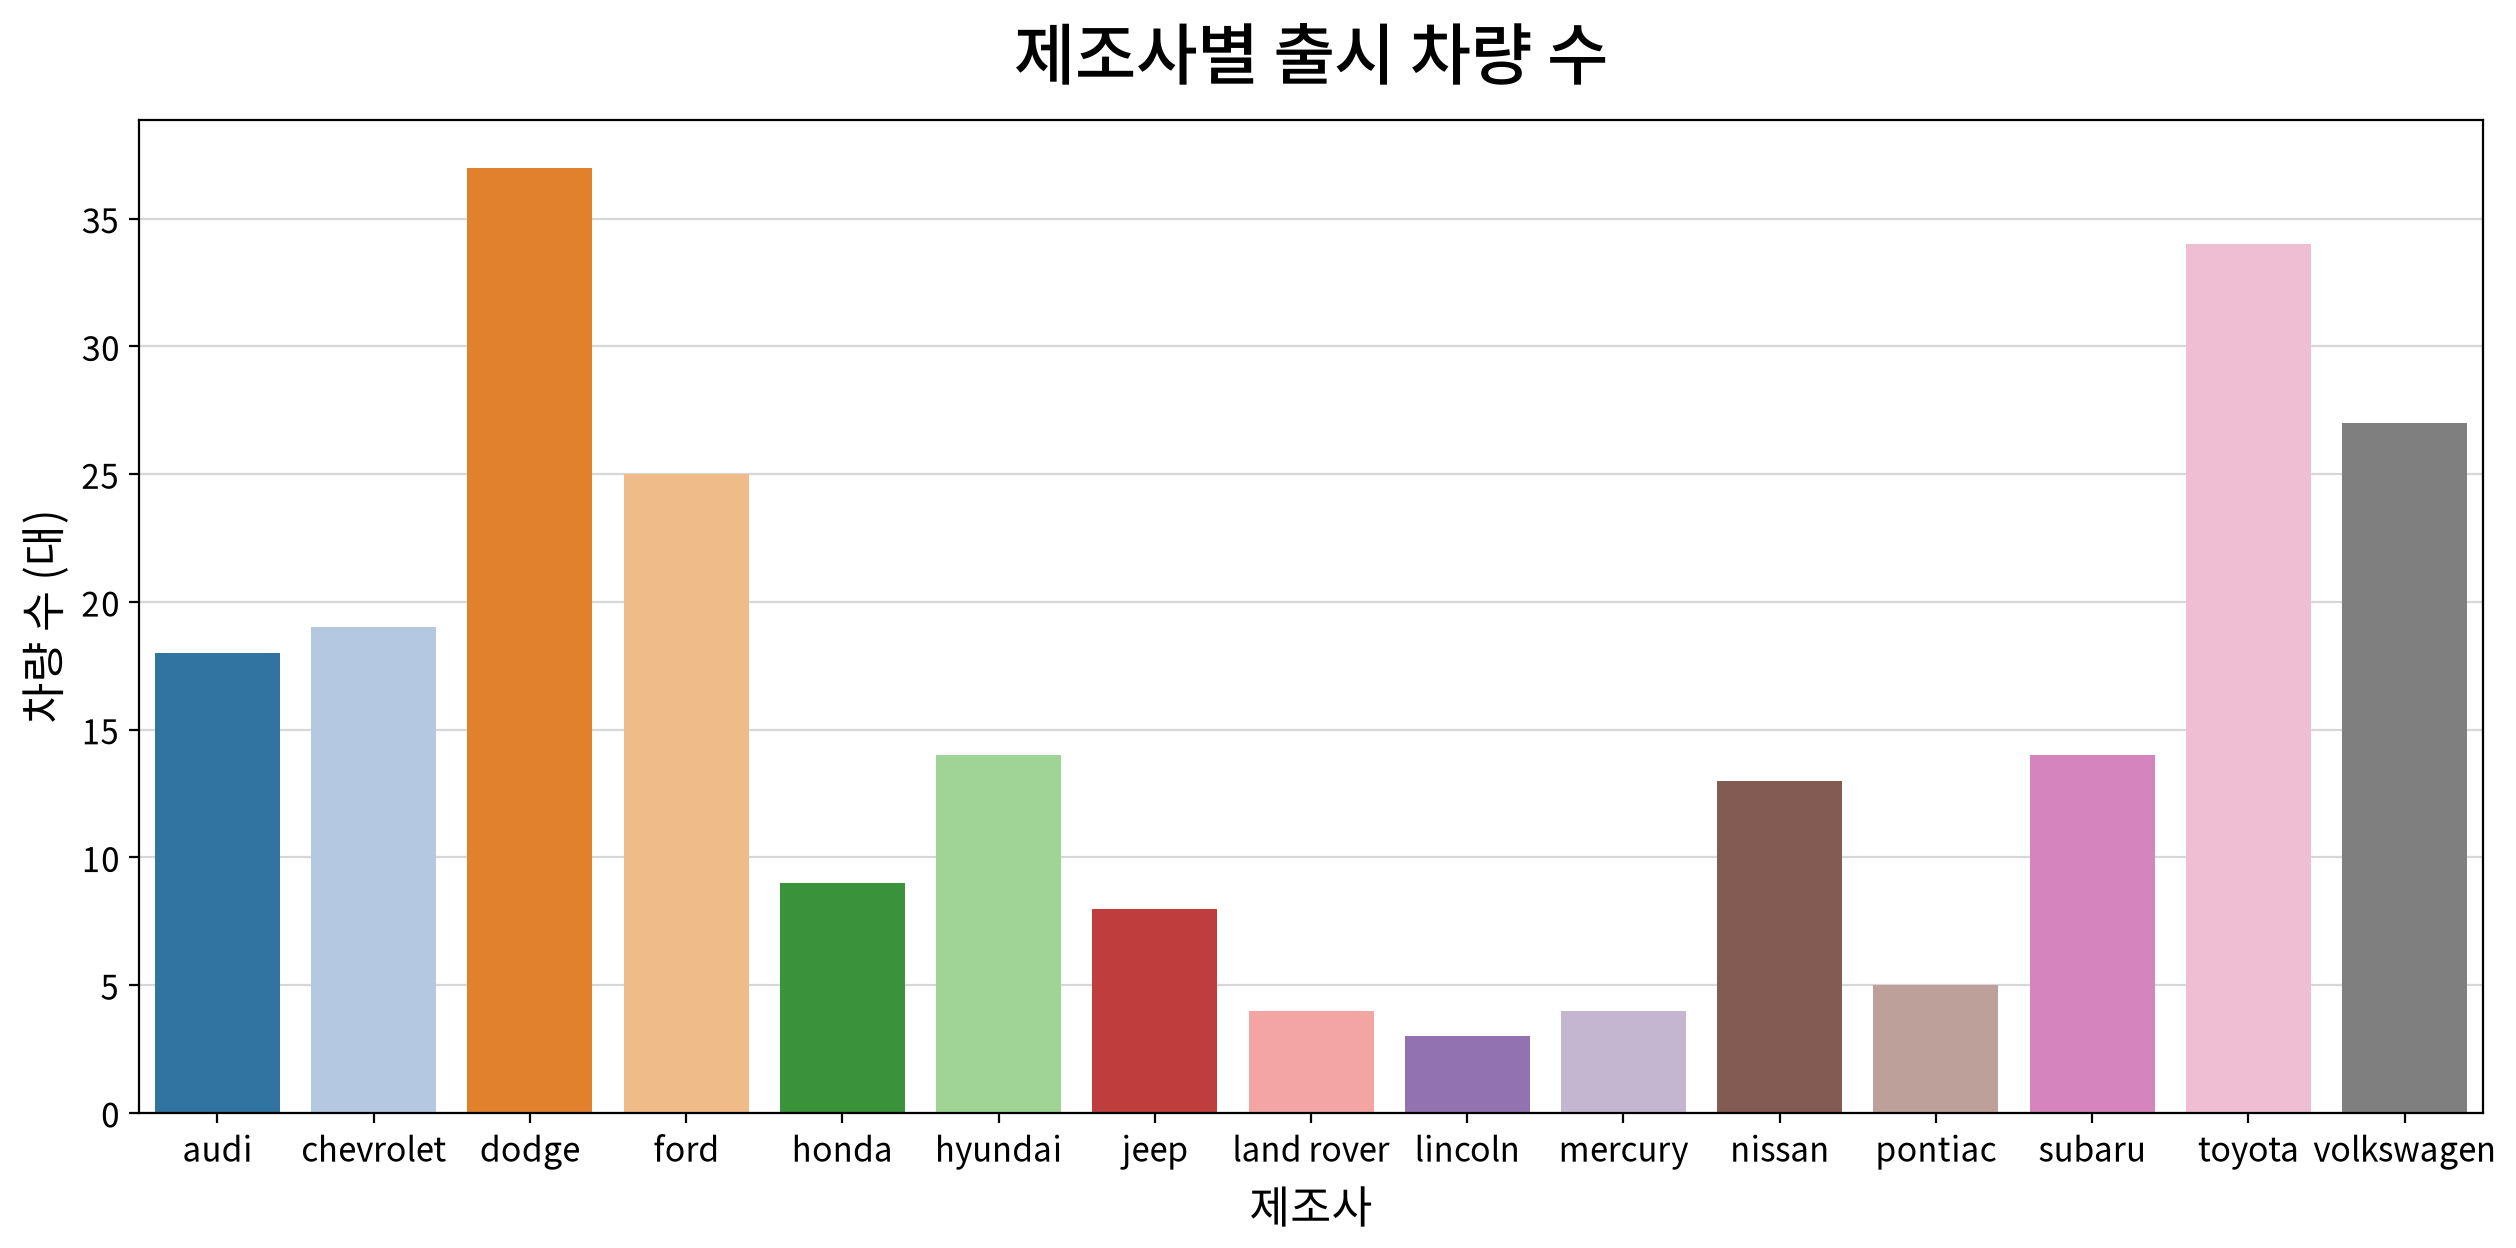

In [5]:
my_plot.countplot(data=df, x="manufacturer", palette="tab20",
                  title="제조사별 출시 차량 수", xlabel="제조사", ylabel="차량 수 (대)")

- ② dodge

## 문제 2. 차종(`class`) 중 가장 많은 비중을 차지하는 종류는?

① compact  ② midsize  ③ suv  ④ pickup

> 💡 **힌트**: 막대그래프 또는 원그래프 (차종별 빈도)

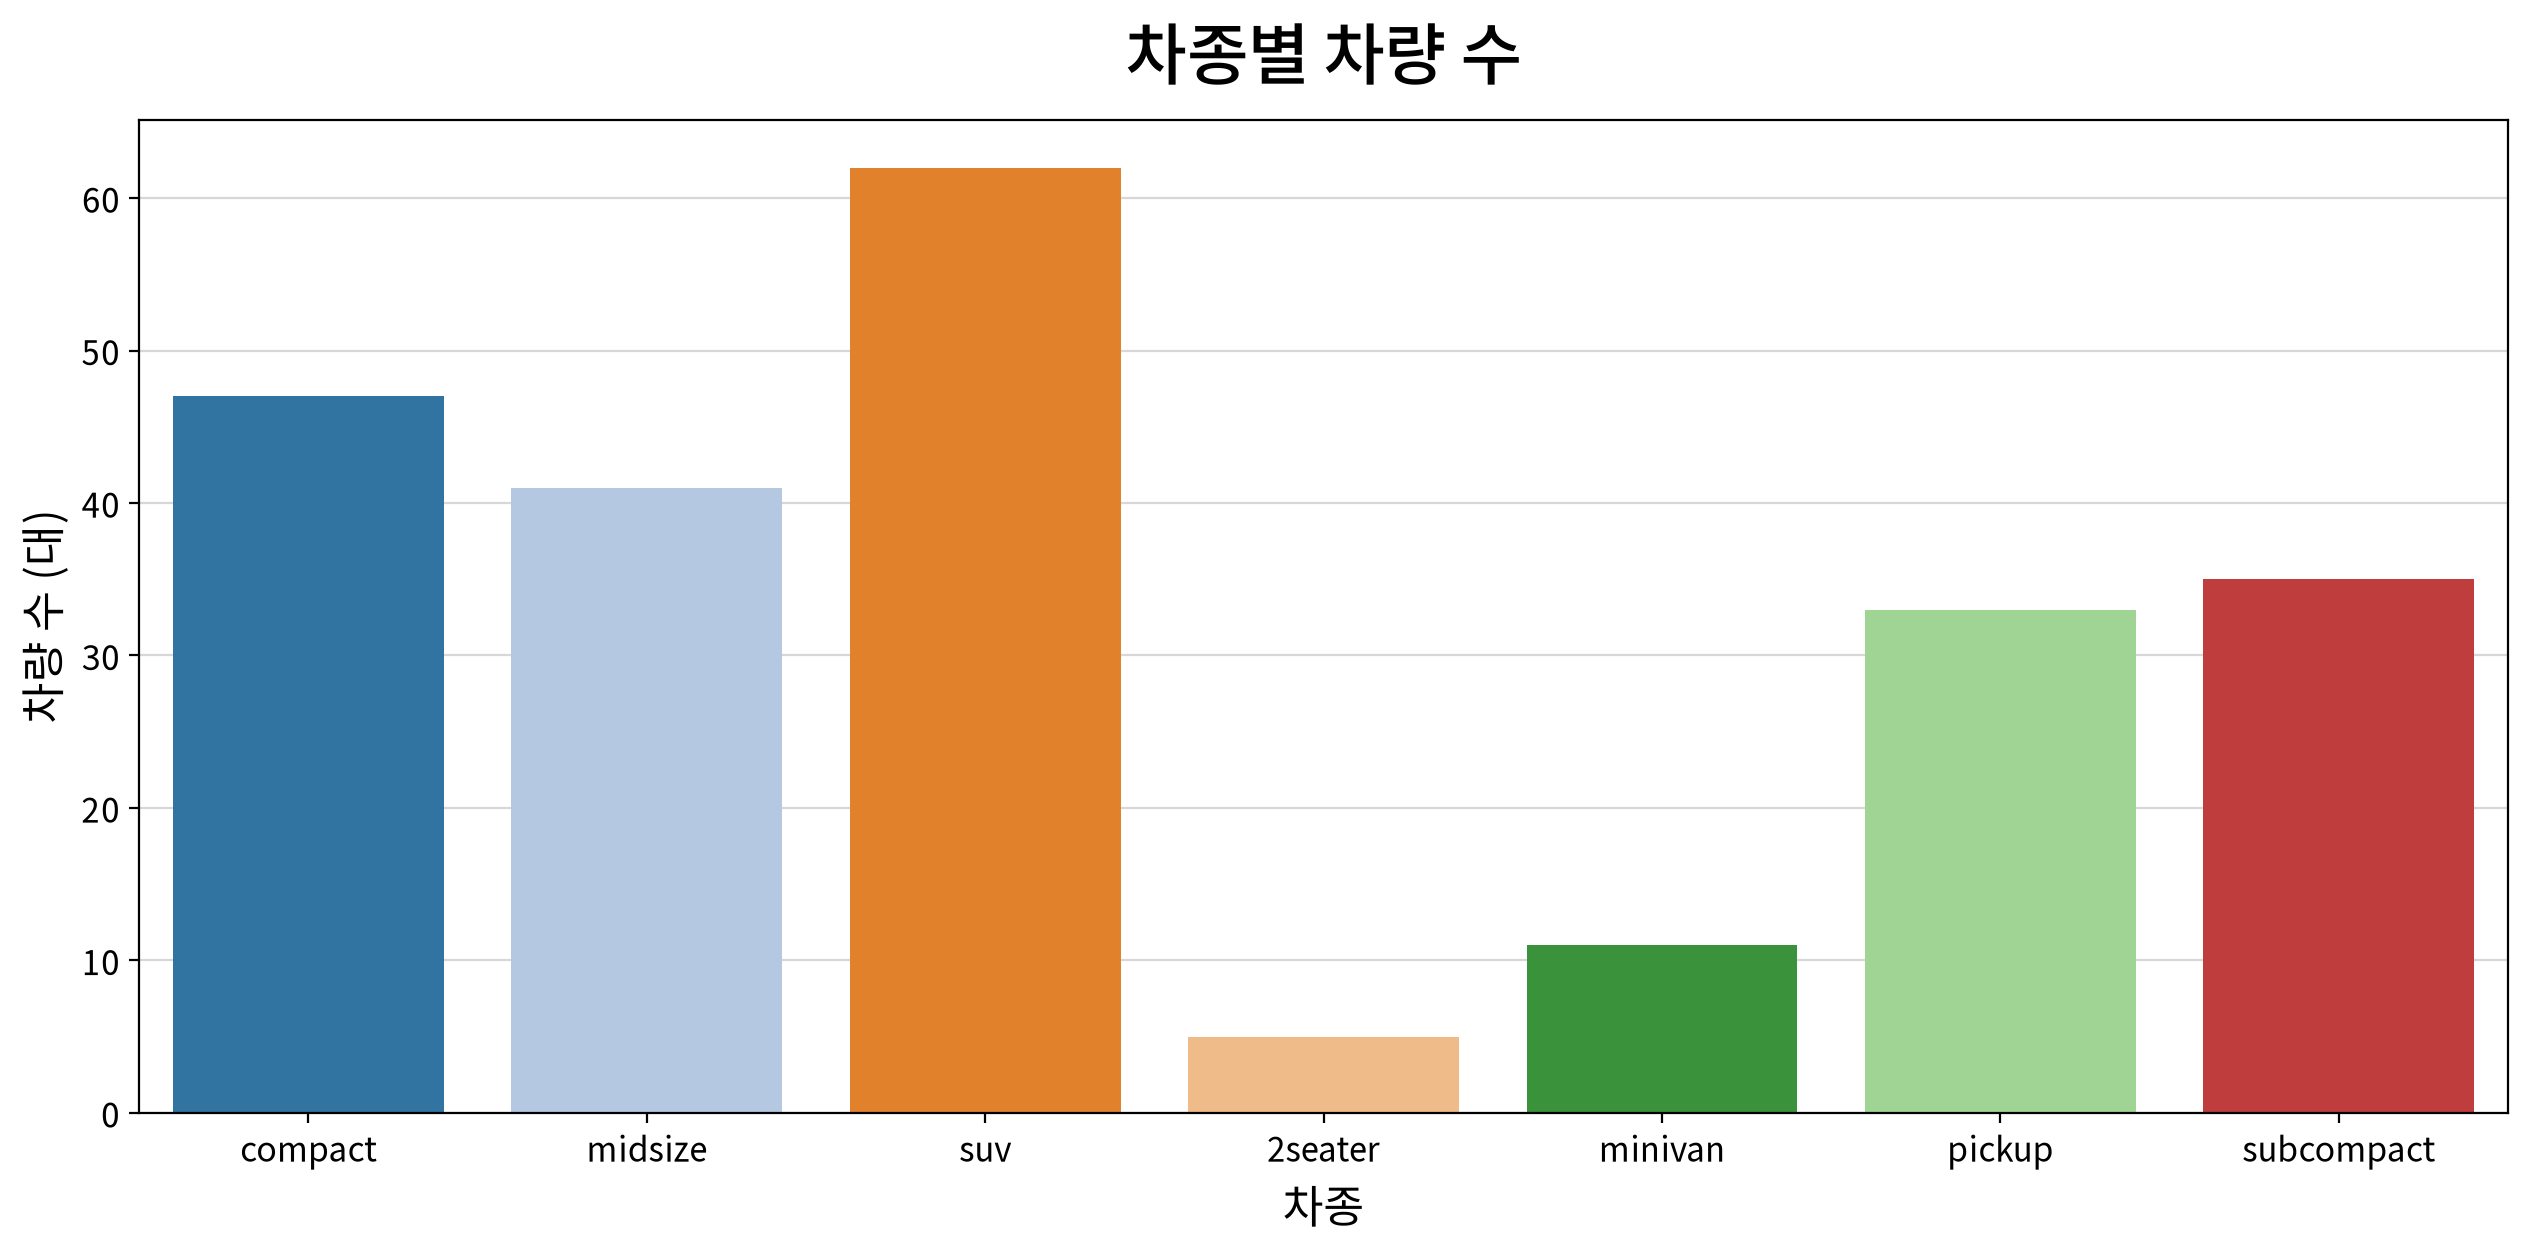

In [6]:
my_plot.countplot(data=df, x="class", palette="tab20",
                  title="차종별 차량 수", xlabel="차종", ylabel="차량 수 (대)")

- ③ suv

## 문제 3. 구동방식(`drv`) 중 차량 수가 가장 적은 방식은?

① 전륜구동  ② 4륜구동  ③ 후륜구동  ④ 모두 동일

> 💡 **힌트**: 막대그래프 (구동방식별 빈도)

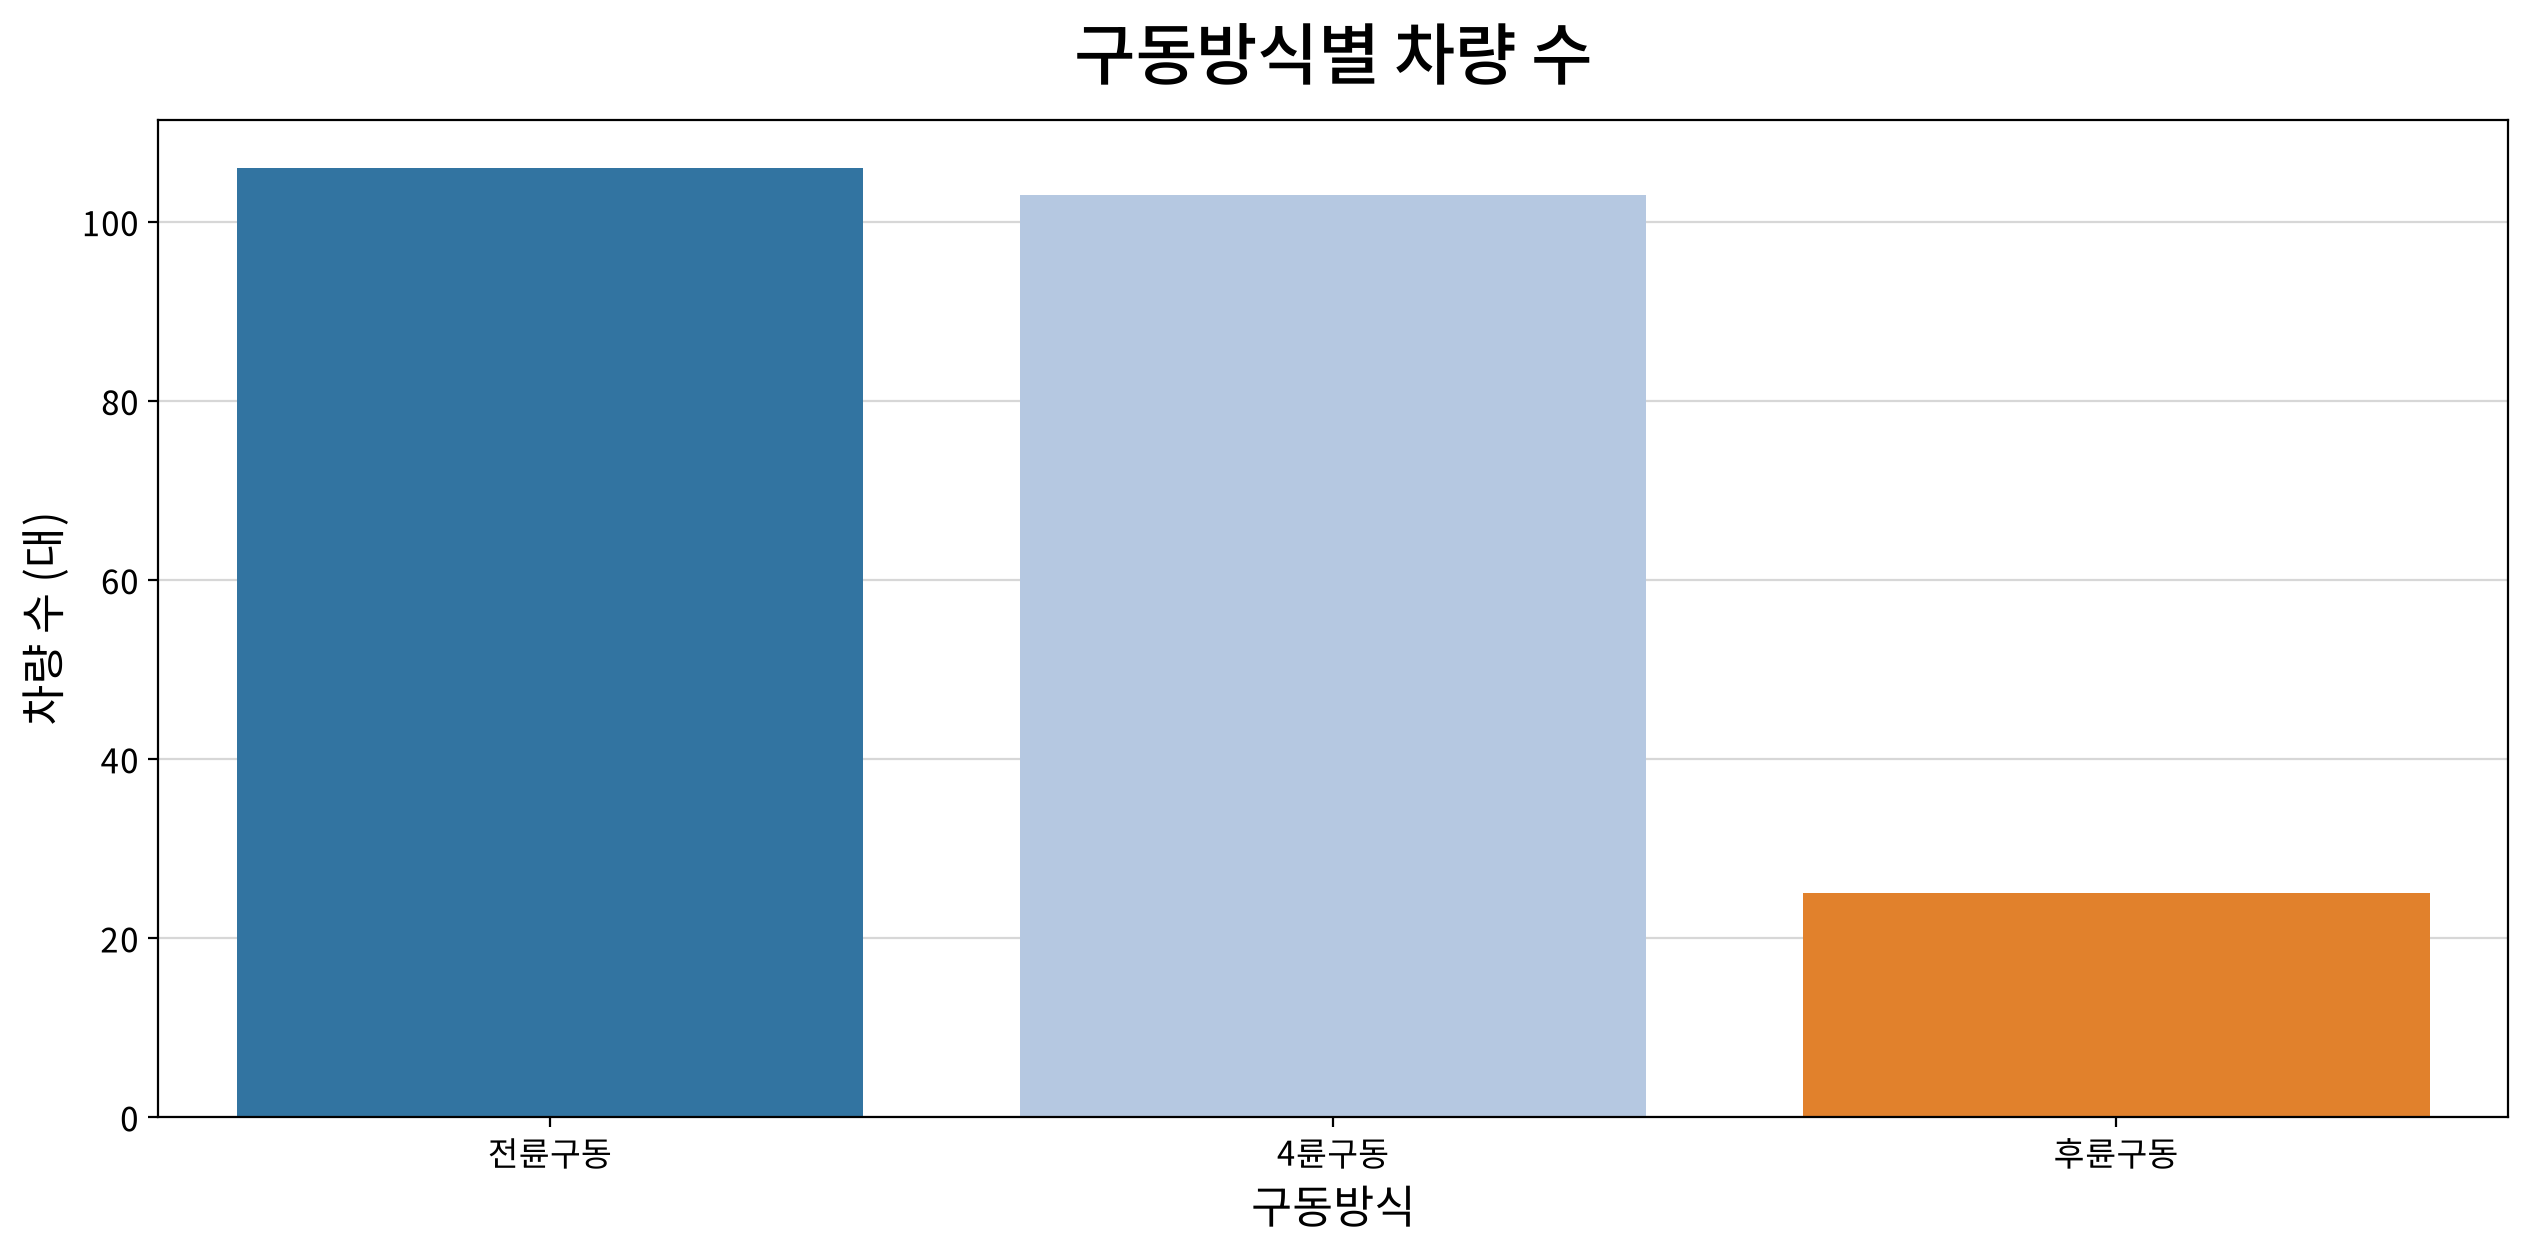

In [7]:
my_plot.countplot(data=df, x="drv", palette="tab20",
                  title="구동방식별 차량 수", xlabel="구동방식", ylabel="차량 수 (대)")

- ③ 후륜구동

## 문제 4. 도심 연비(`cty`) 평균이 가장 높은 구동방식은?

① 전륜구동  ② 4륜구동  ③ 후륜구동  ④ 모두 비슷

> 💡 **힌트**: 막대그래프 (구동방식별 cty 평균)

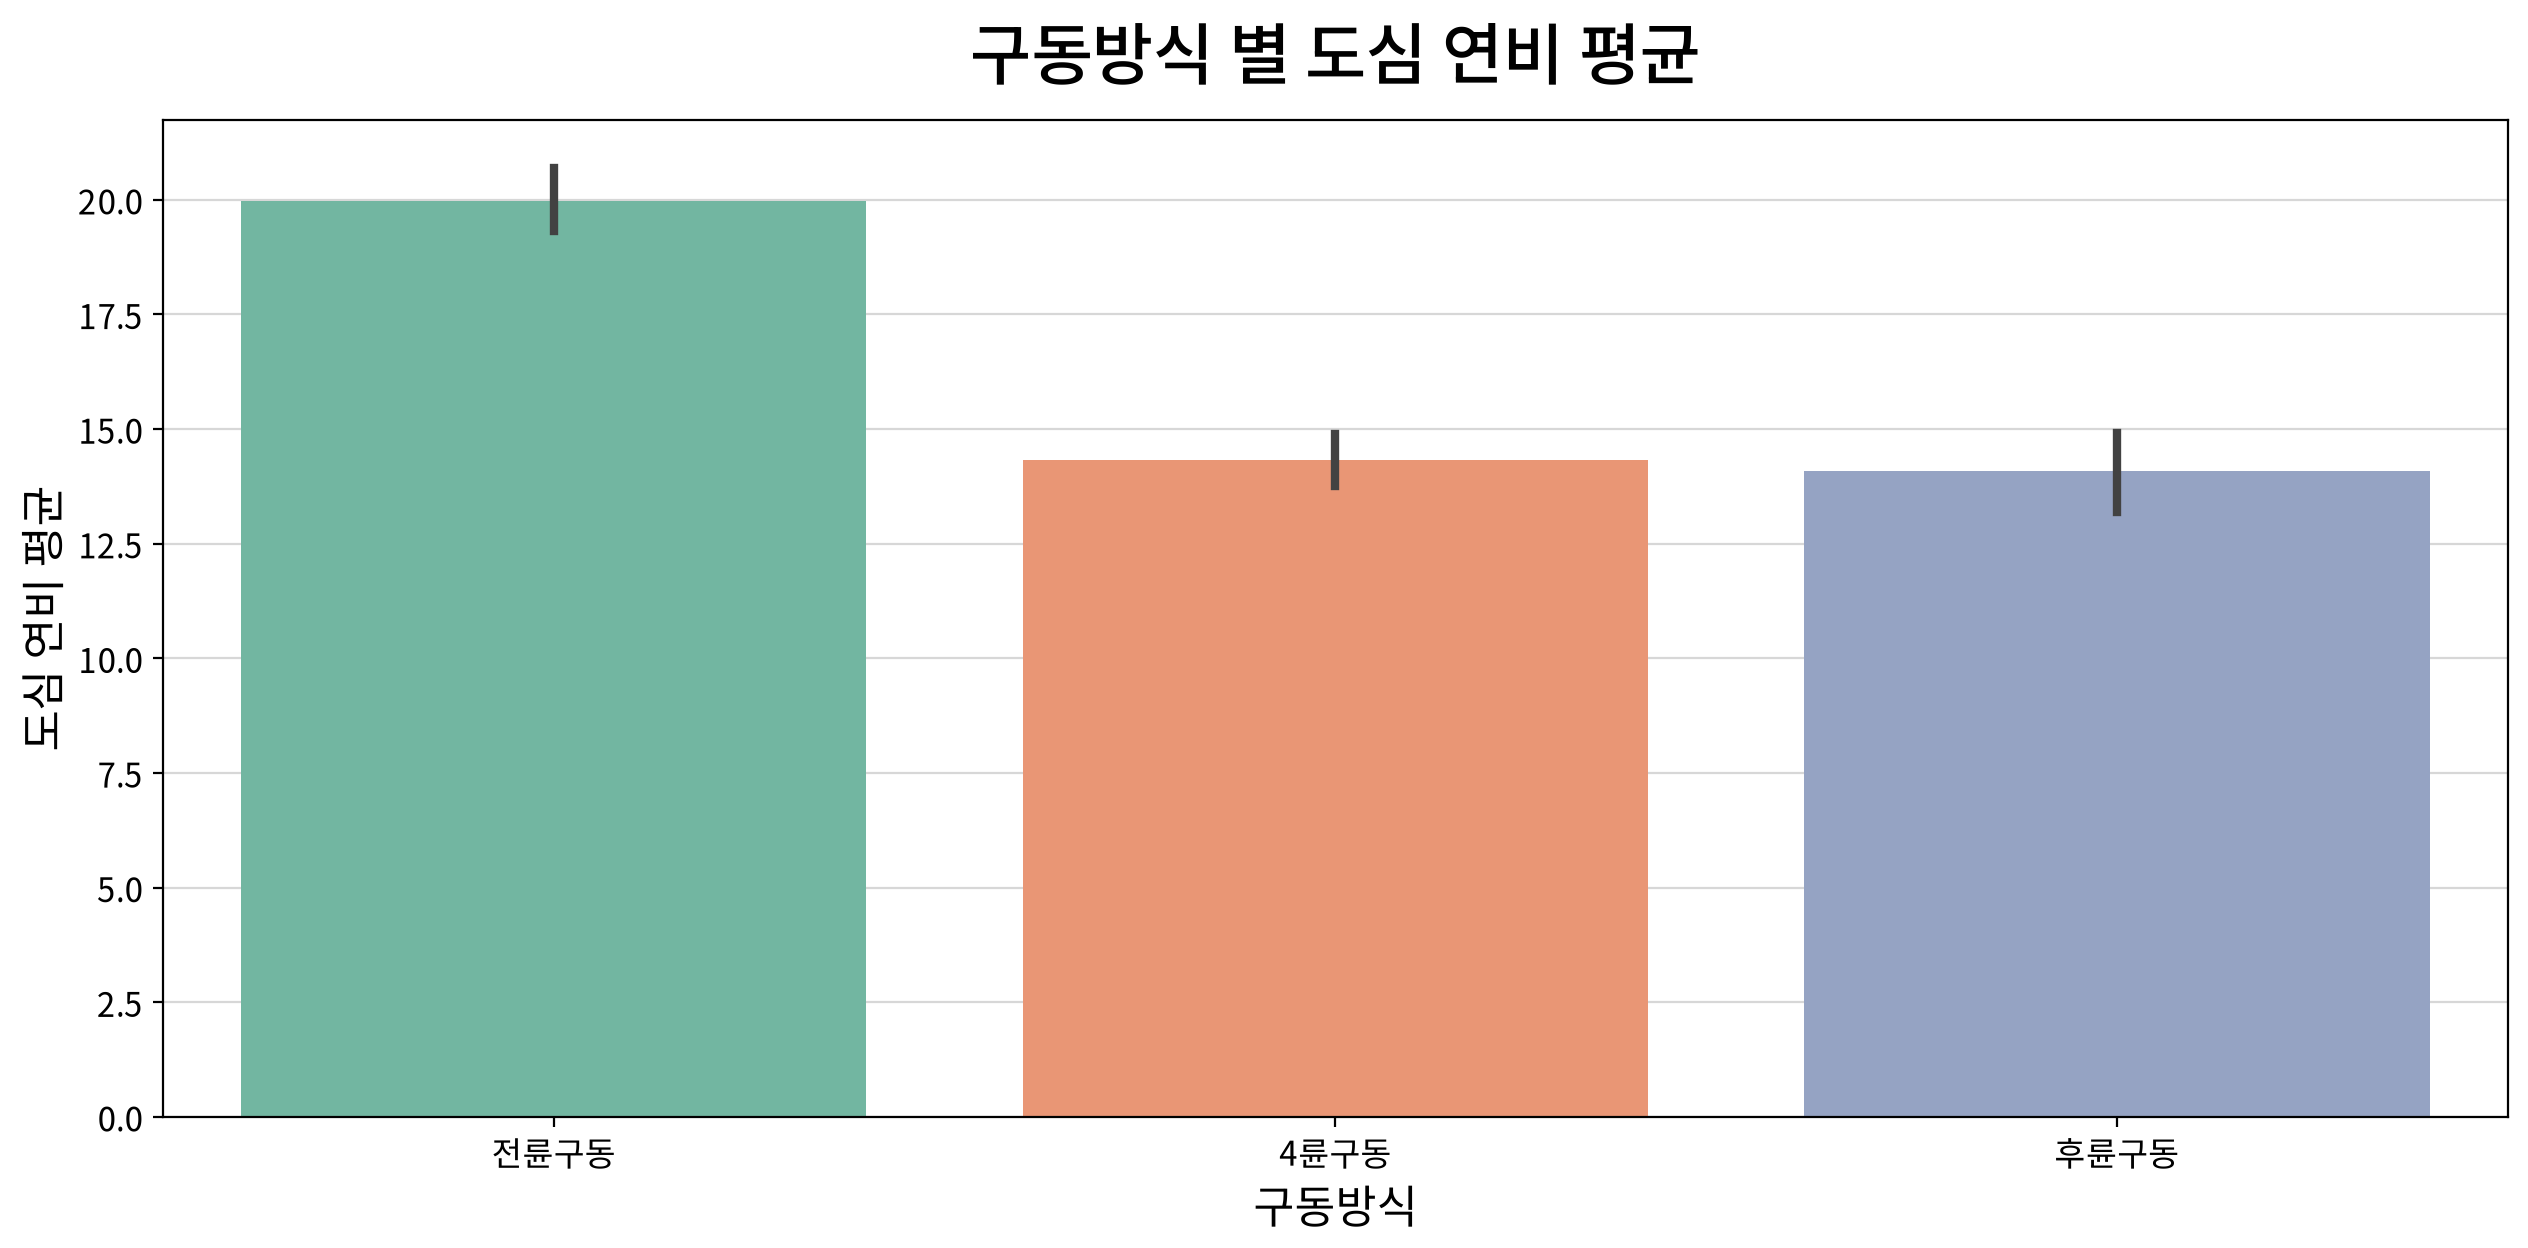

In [8]:
my_plot.barplot(data=df, x="drv", y="cty",
                estimator=np.mean, palette="Set2",
                title="구동방식 별 도심 연비 평균", xlabel="구동방식", ylabel="도심 연비 평균")

- ① 전륜구동

## 문제 5. 실린더 수(`cyl`)가 많아질수록 고속도로 연비(`hwy`)는 어떤 경향을 보이는가?

① 증가한다  ② 감소한다  ③ 관계가 없다  ④ U자 형태

> 💡 **힌트**: 막대그래프 (실린더 수별 hwy 평균)

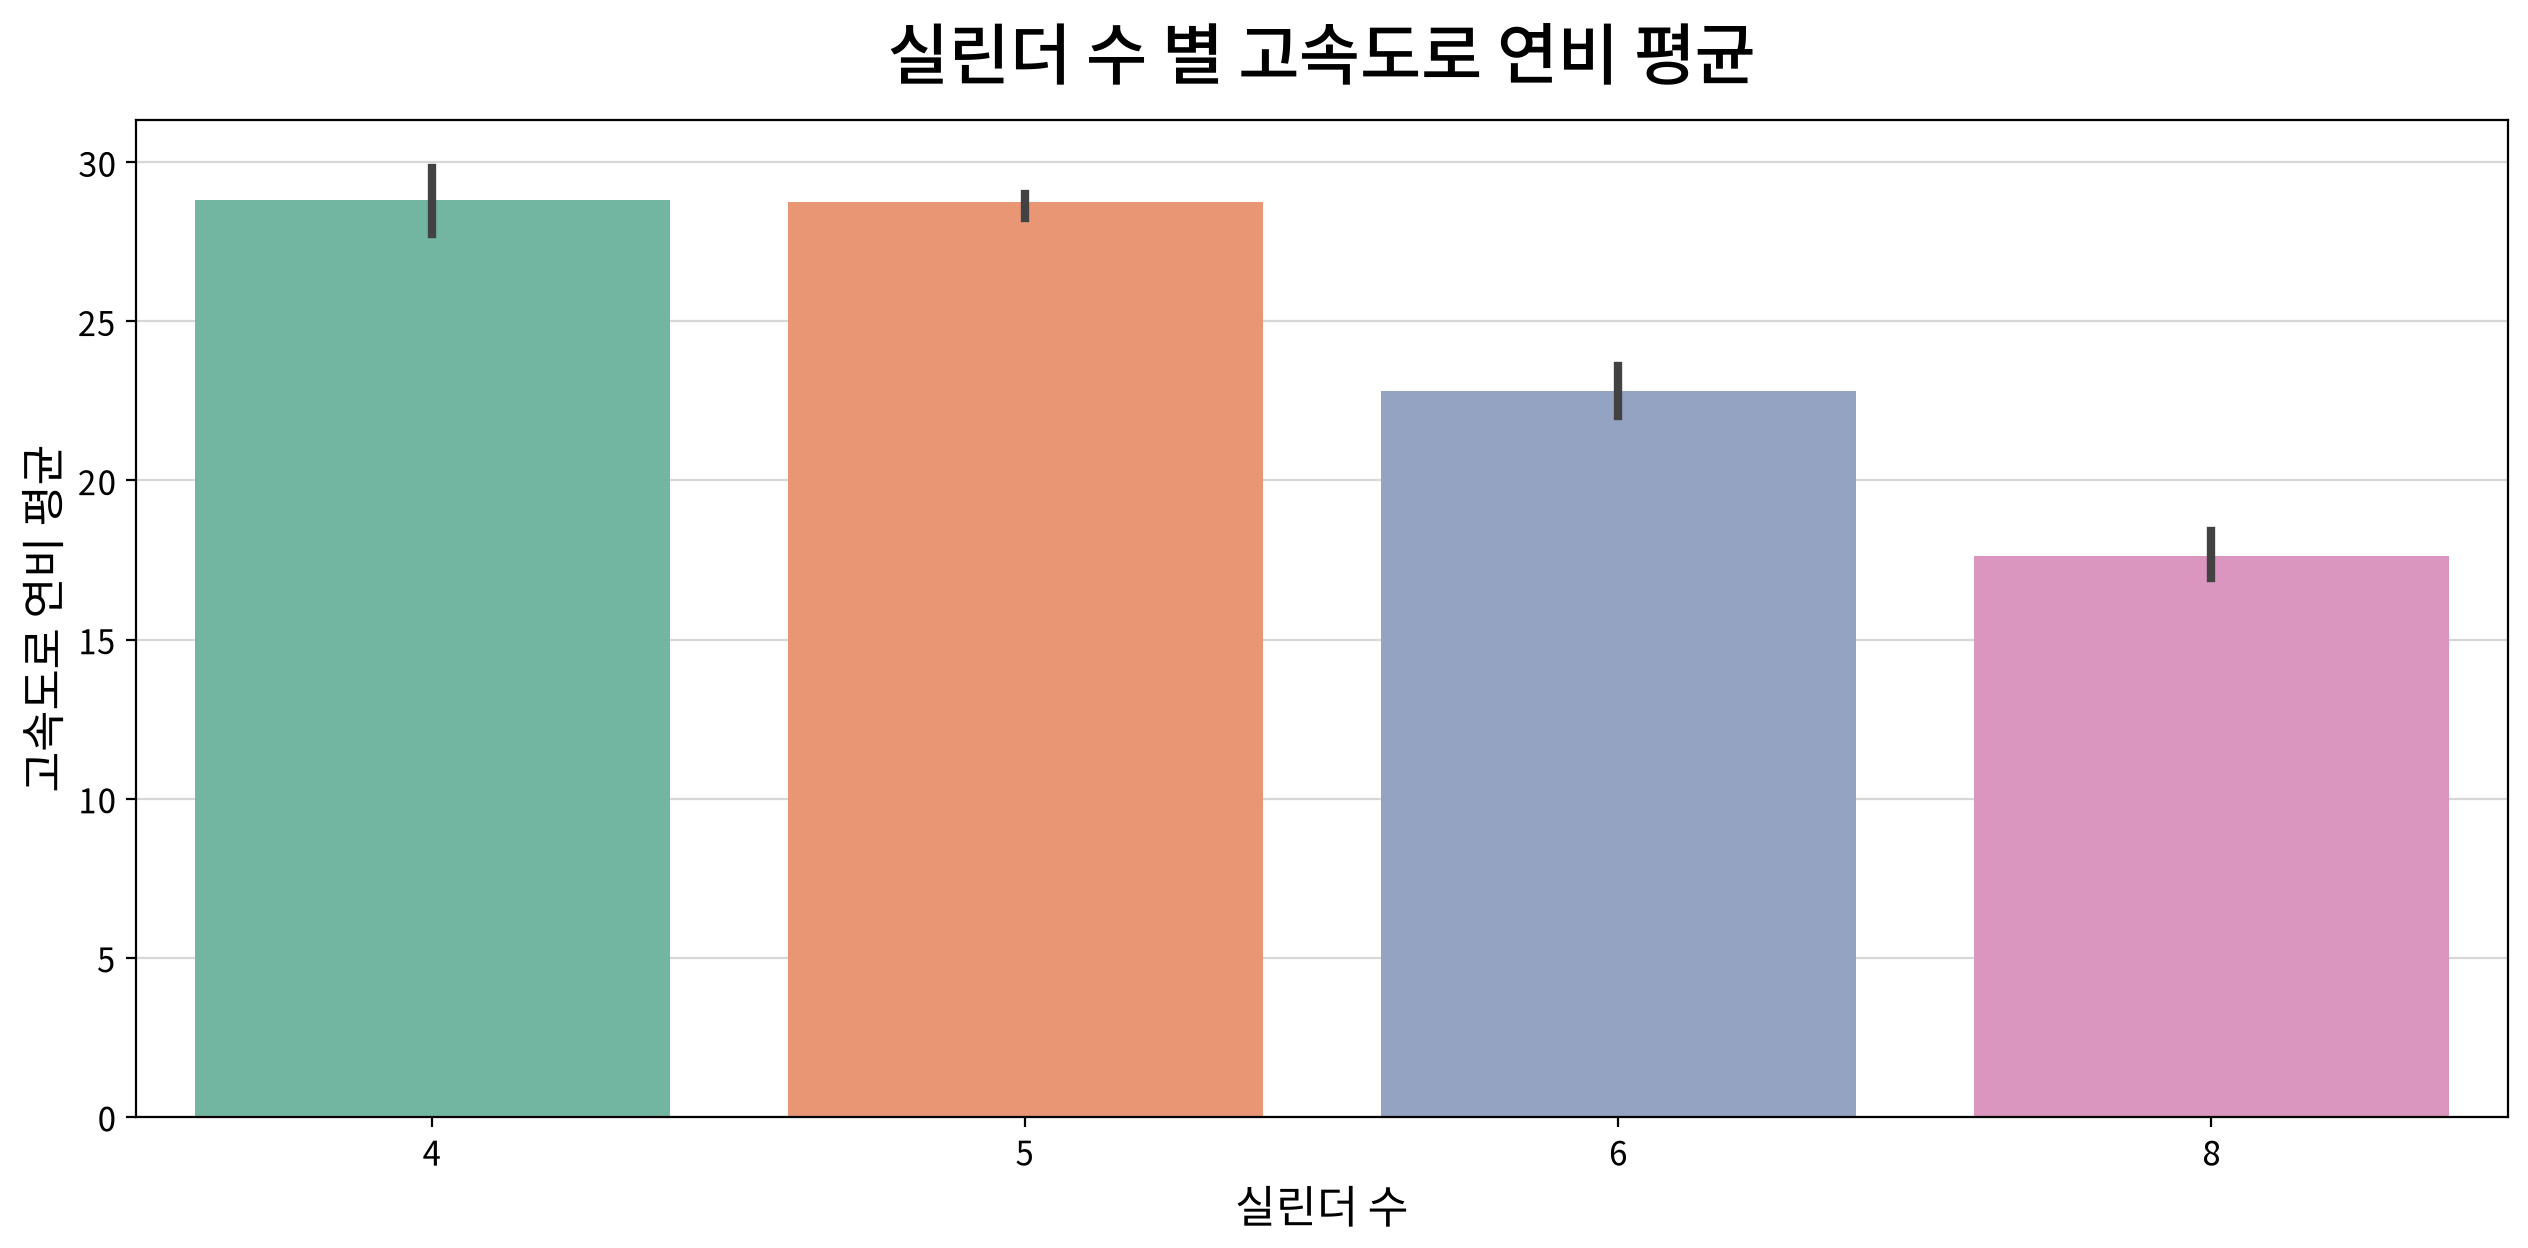

In [9]:
my_plot.barplot(data=df, x="cyl", y="hwy",
                estimator=np.mean, palette="Set2",
                title="실린더 수 별 고속도로 연비 평균", xlabel="실린더 수", ylabel="고속도로 연비 평균")

- ② 감소한다

## 문제 6. 배기량(`displ`)과 고속도로 연비(`hwy`)는 어떤 상관관계를 가지는가?

① 양(+)의 상관  ② 음(−)의 상관  ③ 상관 없음  ④ 곡선(2차) 관계

> 💡 **힌트**: 산점도 (+ 추세선)

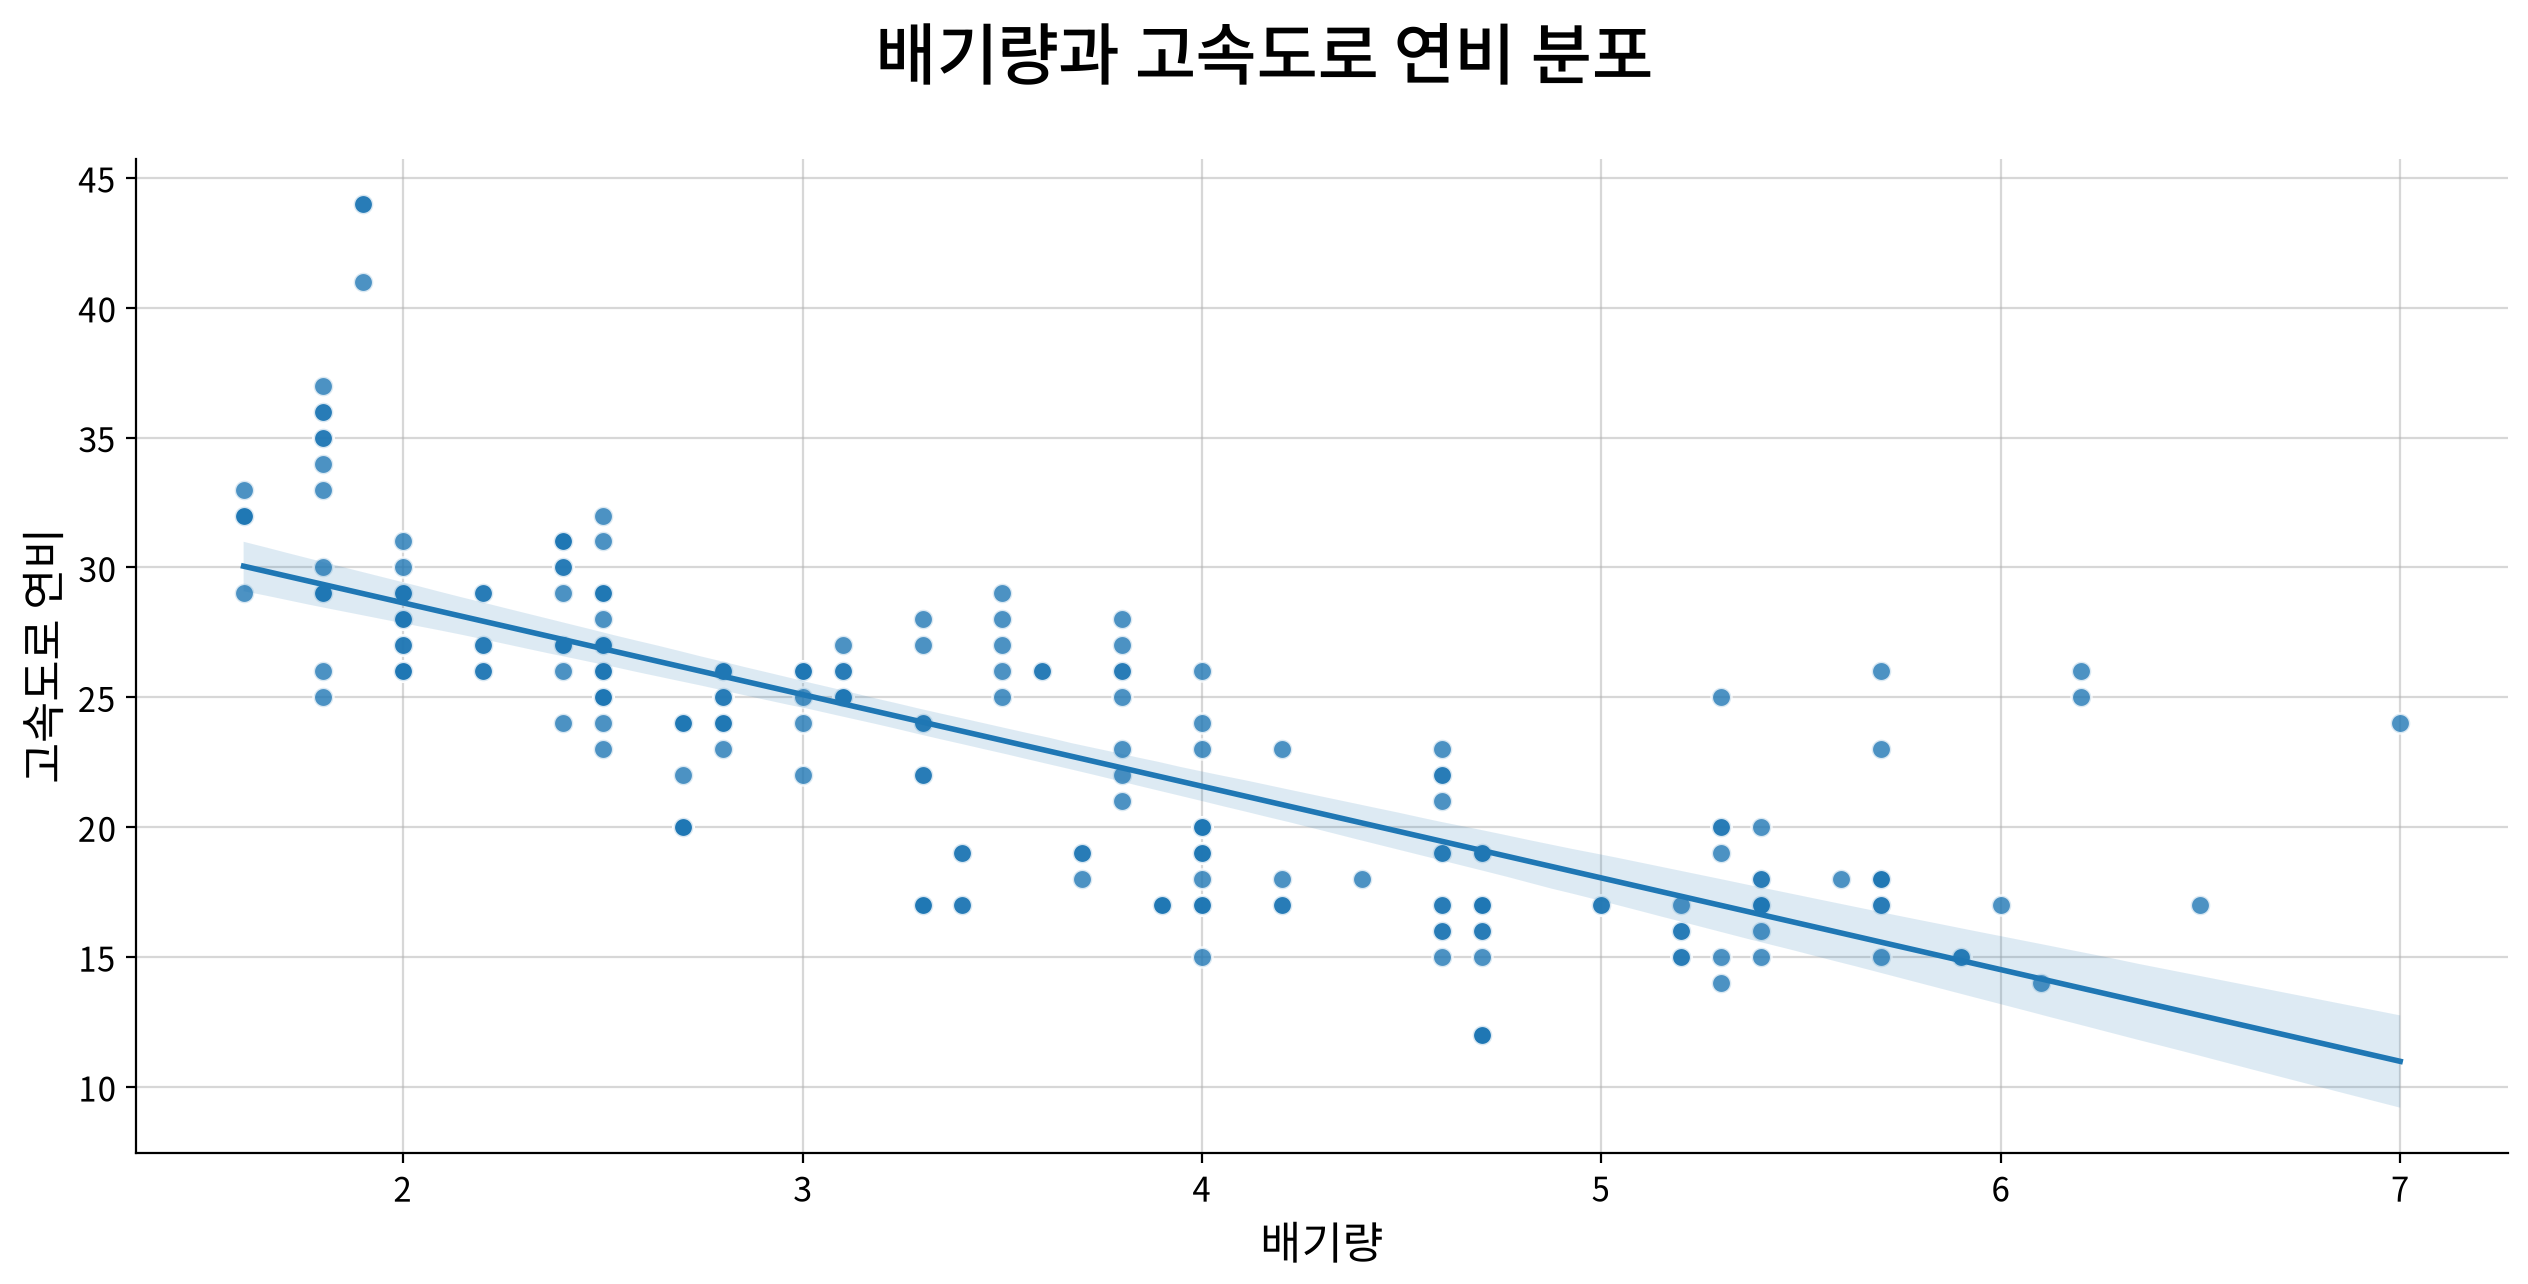

In [10]:
my_plot.lmplot(data=df, x='displ', y='hwy',
               title='배기량과 고속도로 연비 분포',
               xlabel='배기량', ylabel='고속도로 연비')

- ② 음(−)의 상관

## 문제 7. 배기량(`displ`)과 더 강한(추세션의 기울기가 큰) 상관관계를 가지는 연비는?

① 도심 연비(cty)  ② 고속도로 연비(hwy)  ③ 둘이 완전히 동일  ④ 둘 다 상관 없음

> 💡 **힌트**: 산점도 2개를 비교 (+ 추세선)

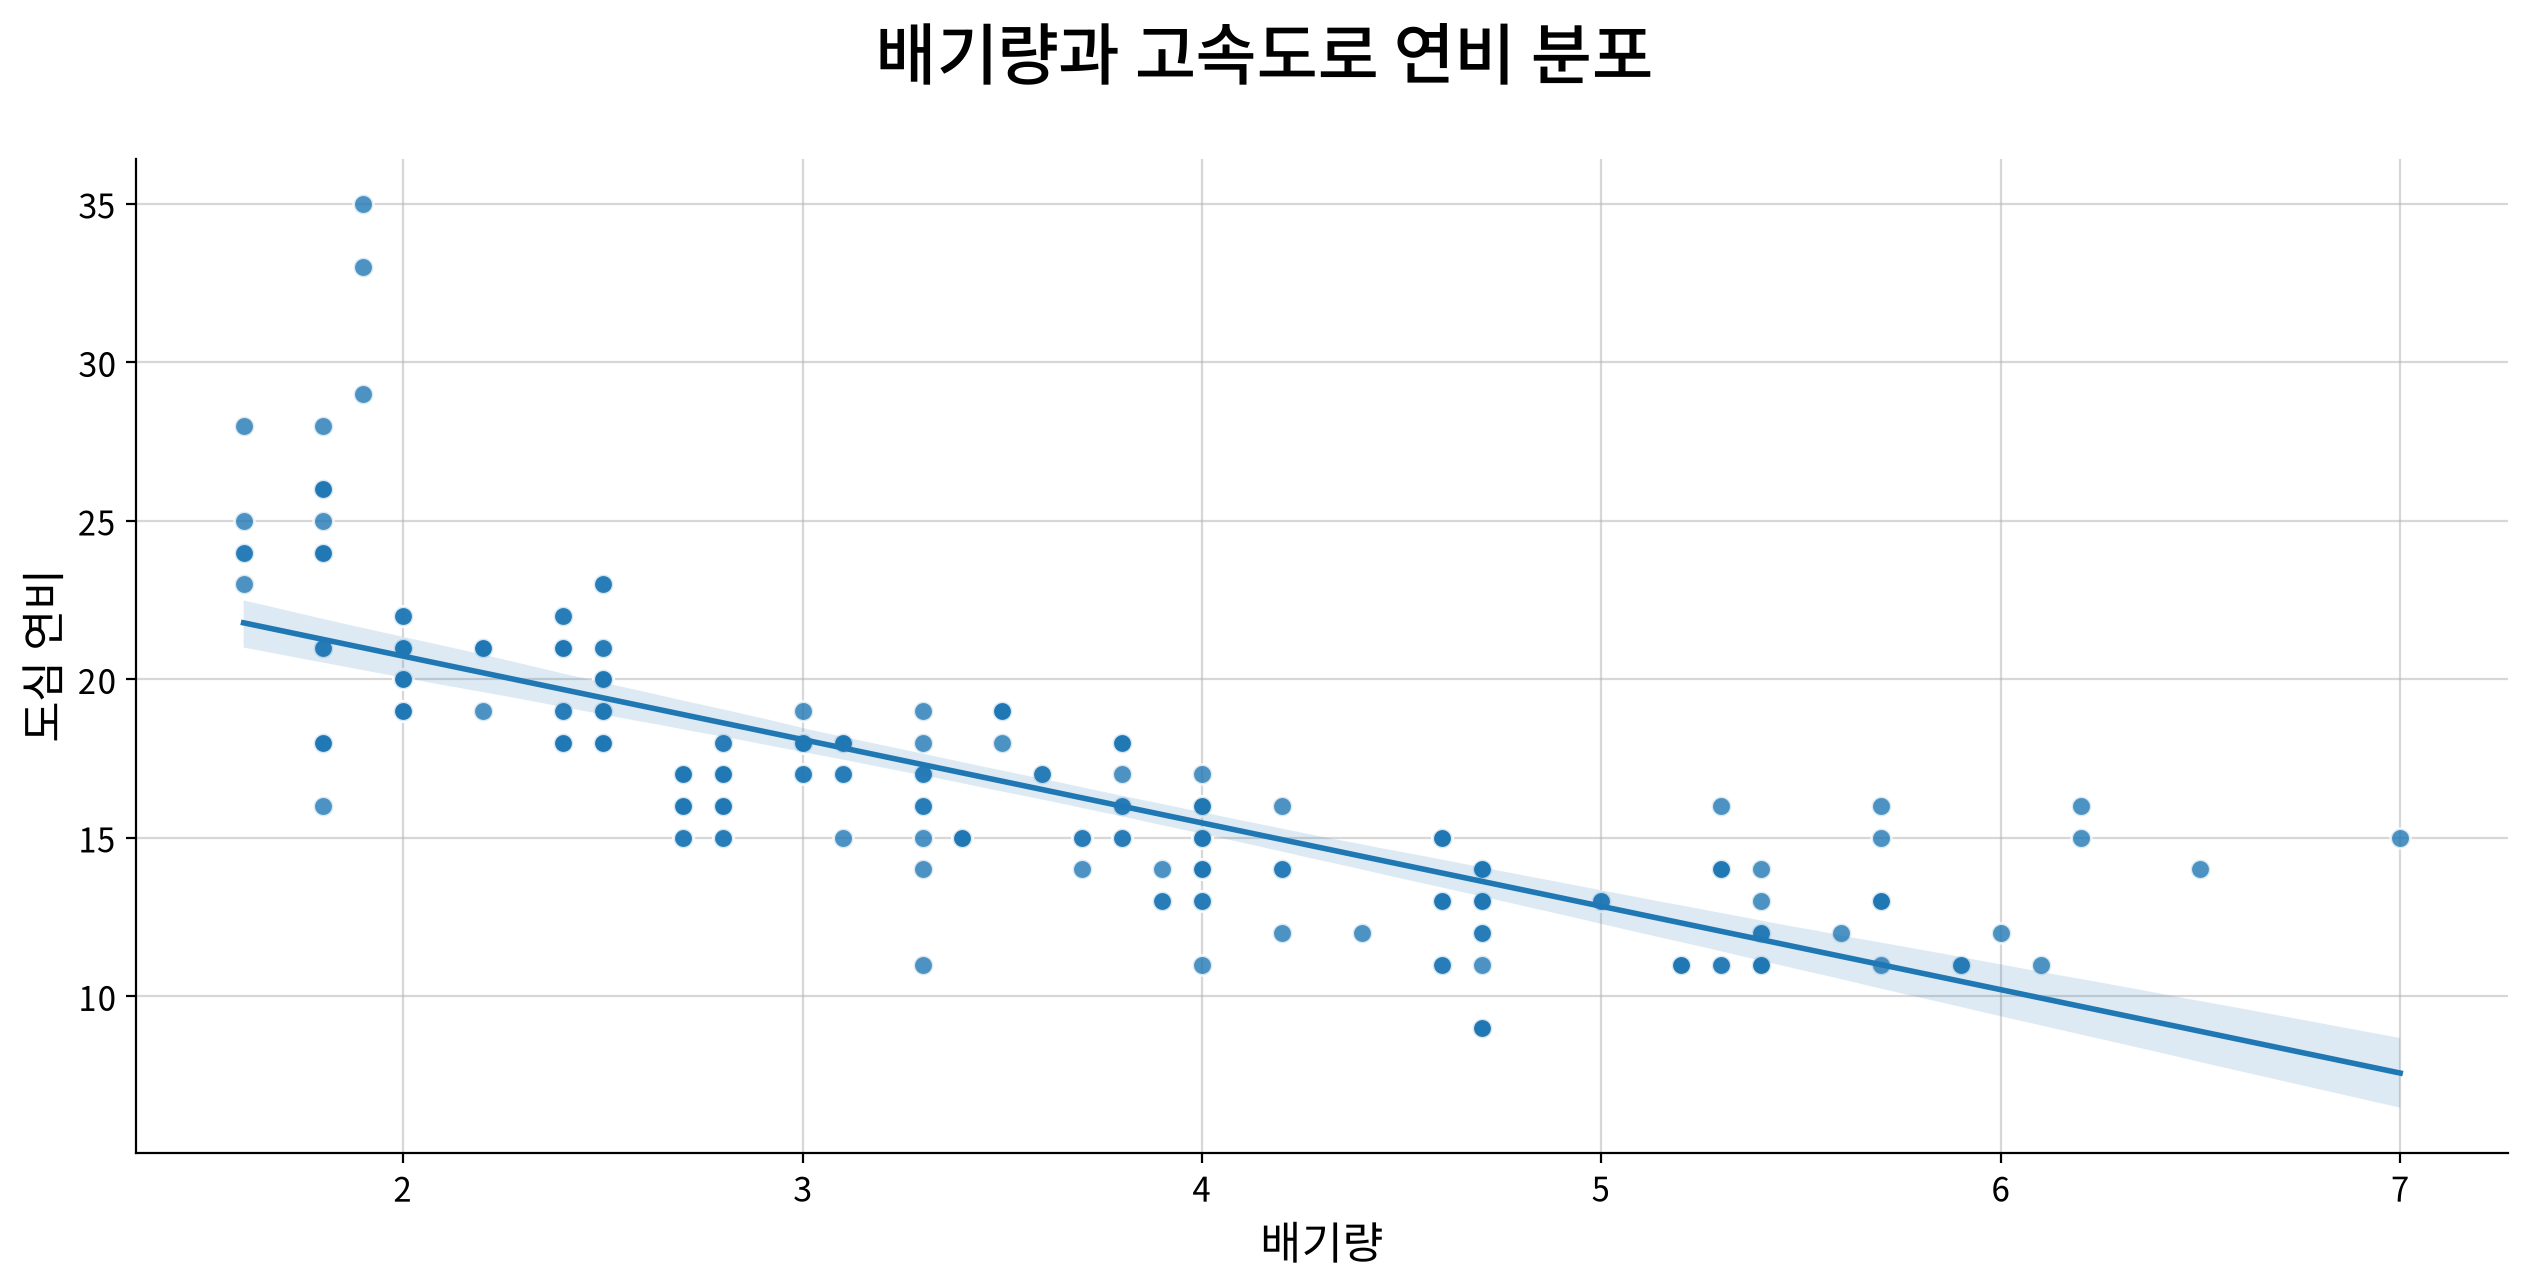

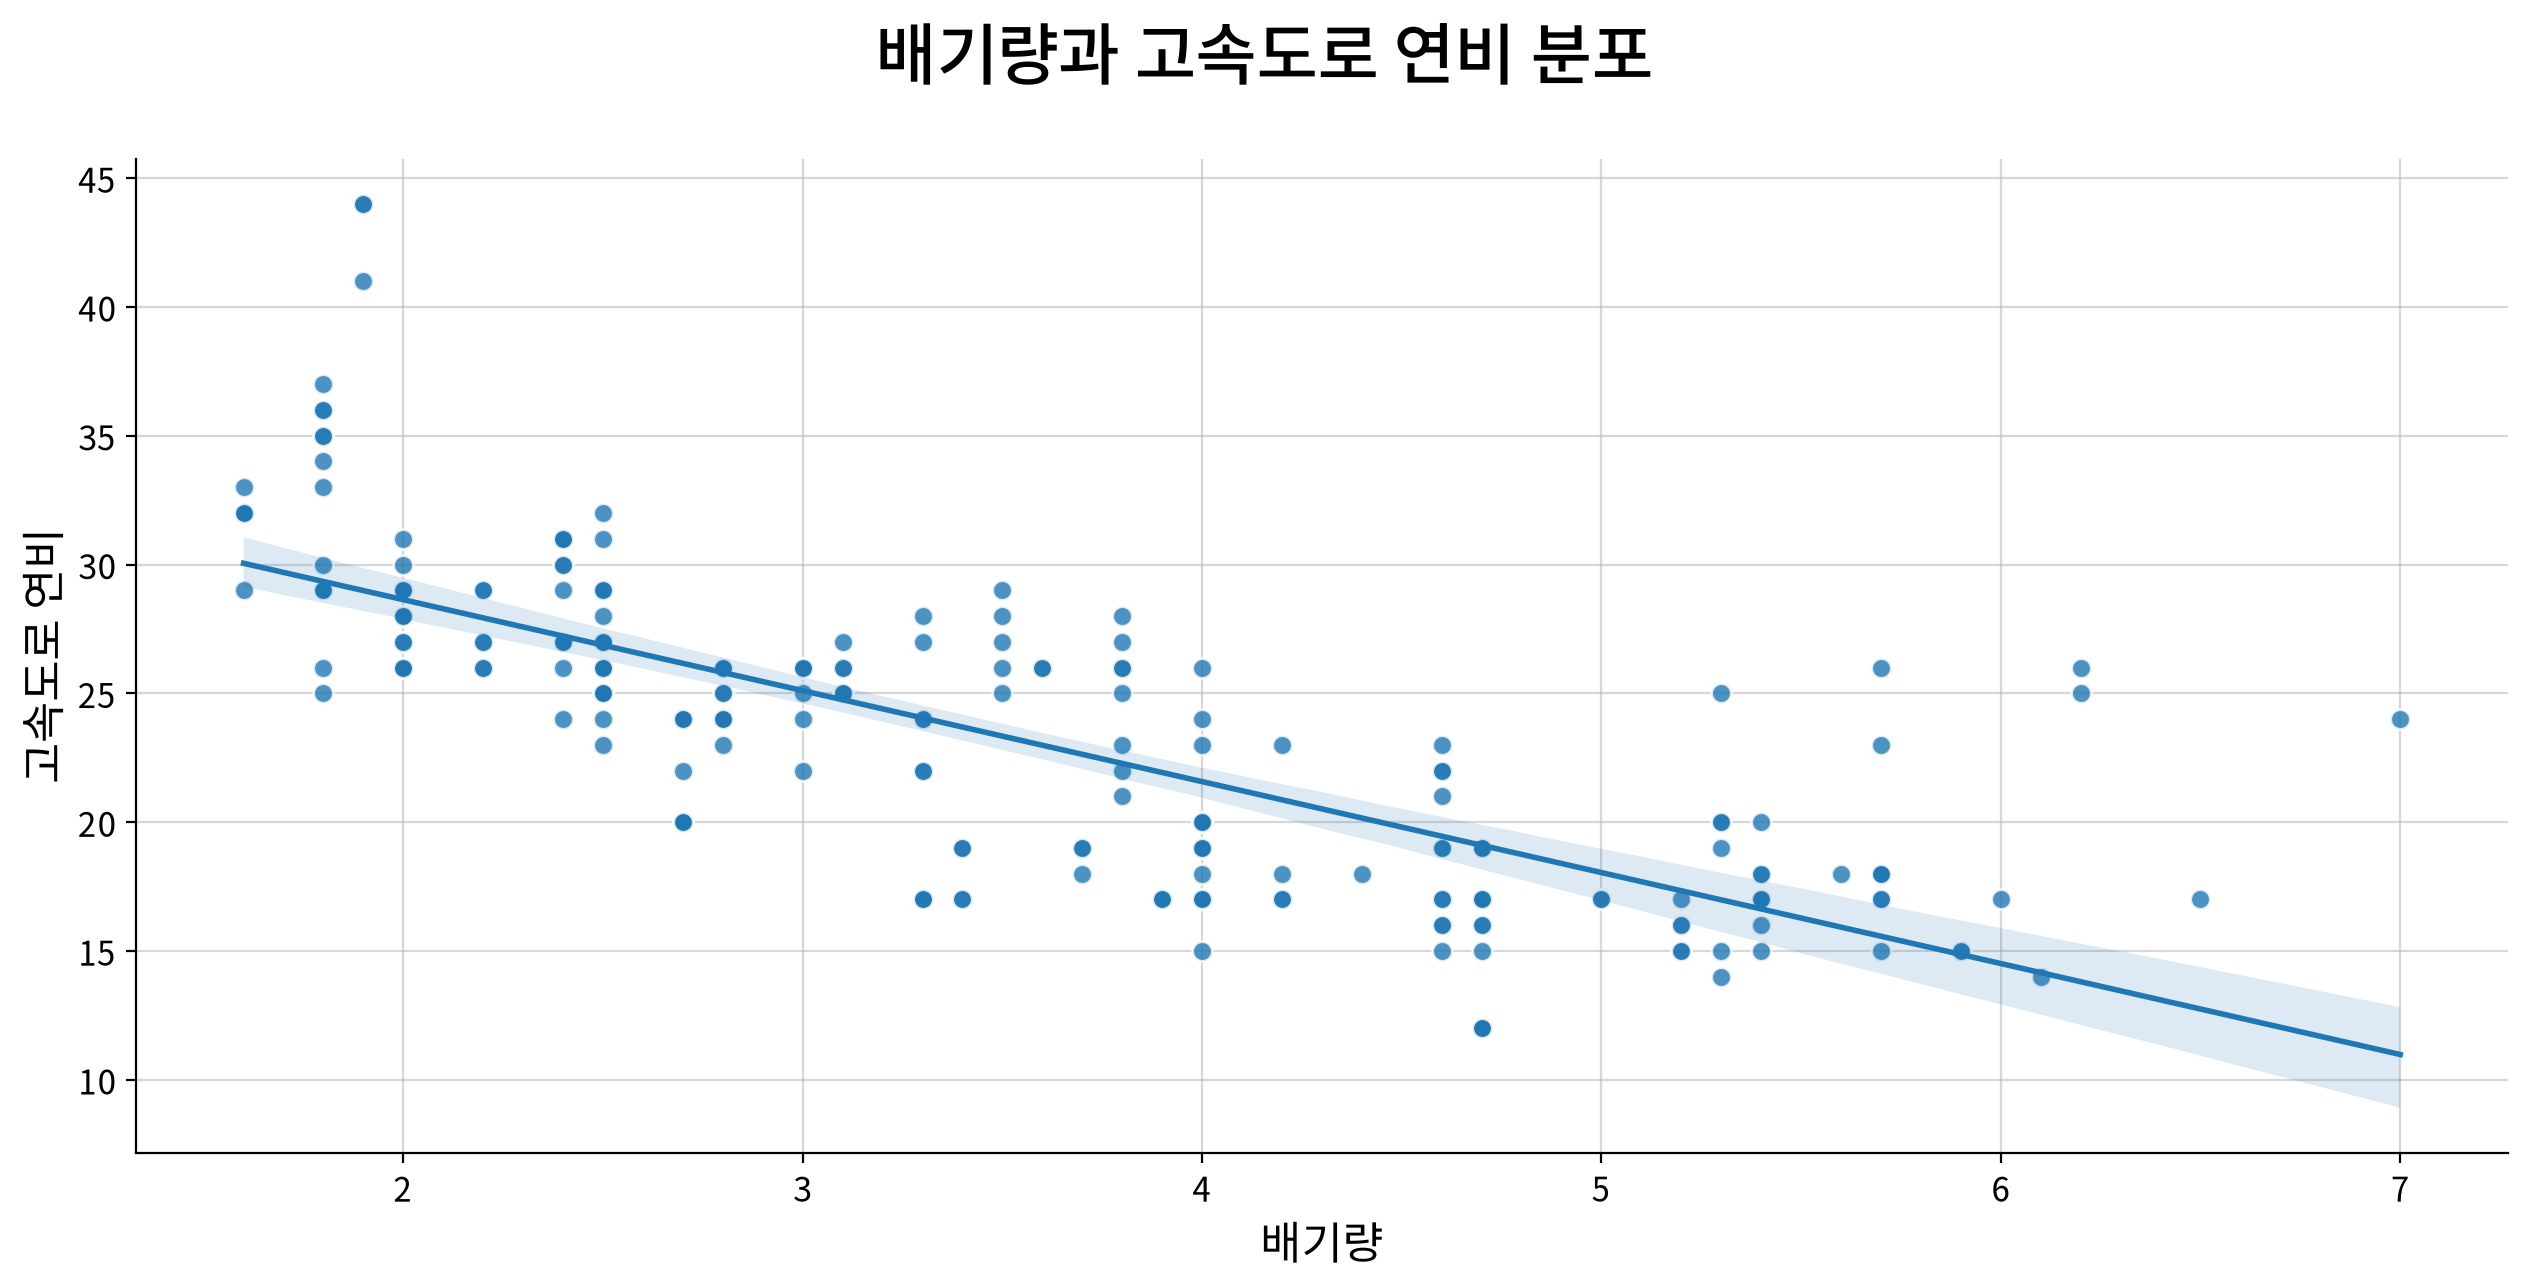

In [11]:
my_plot.lmplot(data=df, x='displ', y='cty',
               title='배기량과 고속도로 연비 분포',
               xlabel='배기량', ylabel='도심 연비')
my_plot.lmplot(data=df, x='displ', y='hwy',
               title='배기량과 고속도로 연비 분포',
               xlabel='배기량', ylabel='고속도로 연비')

- ② 고속도로 연비(hwy)

## 문제 8. 차종(`class`) 중 고속도로 연비(`hwy`) 평균이 가장 낮은 종류는?

① suv  ② pickup  ③ minivan  ④ midsize

> 💡 **힌트**: 막대그래프 (차종별 hwy 평균)

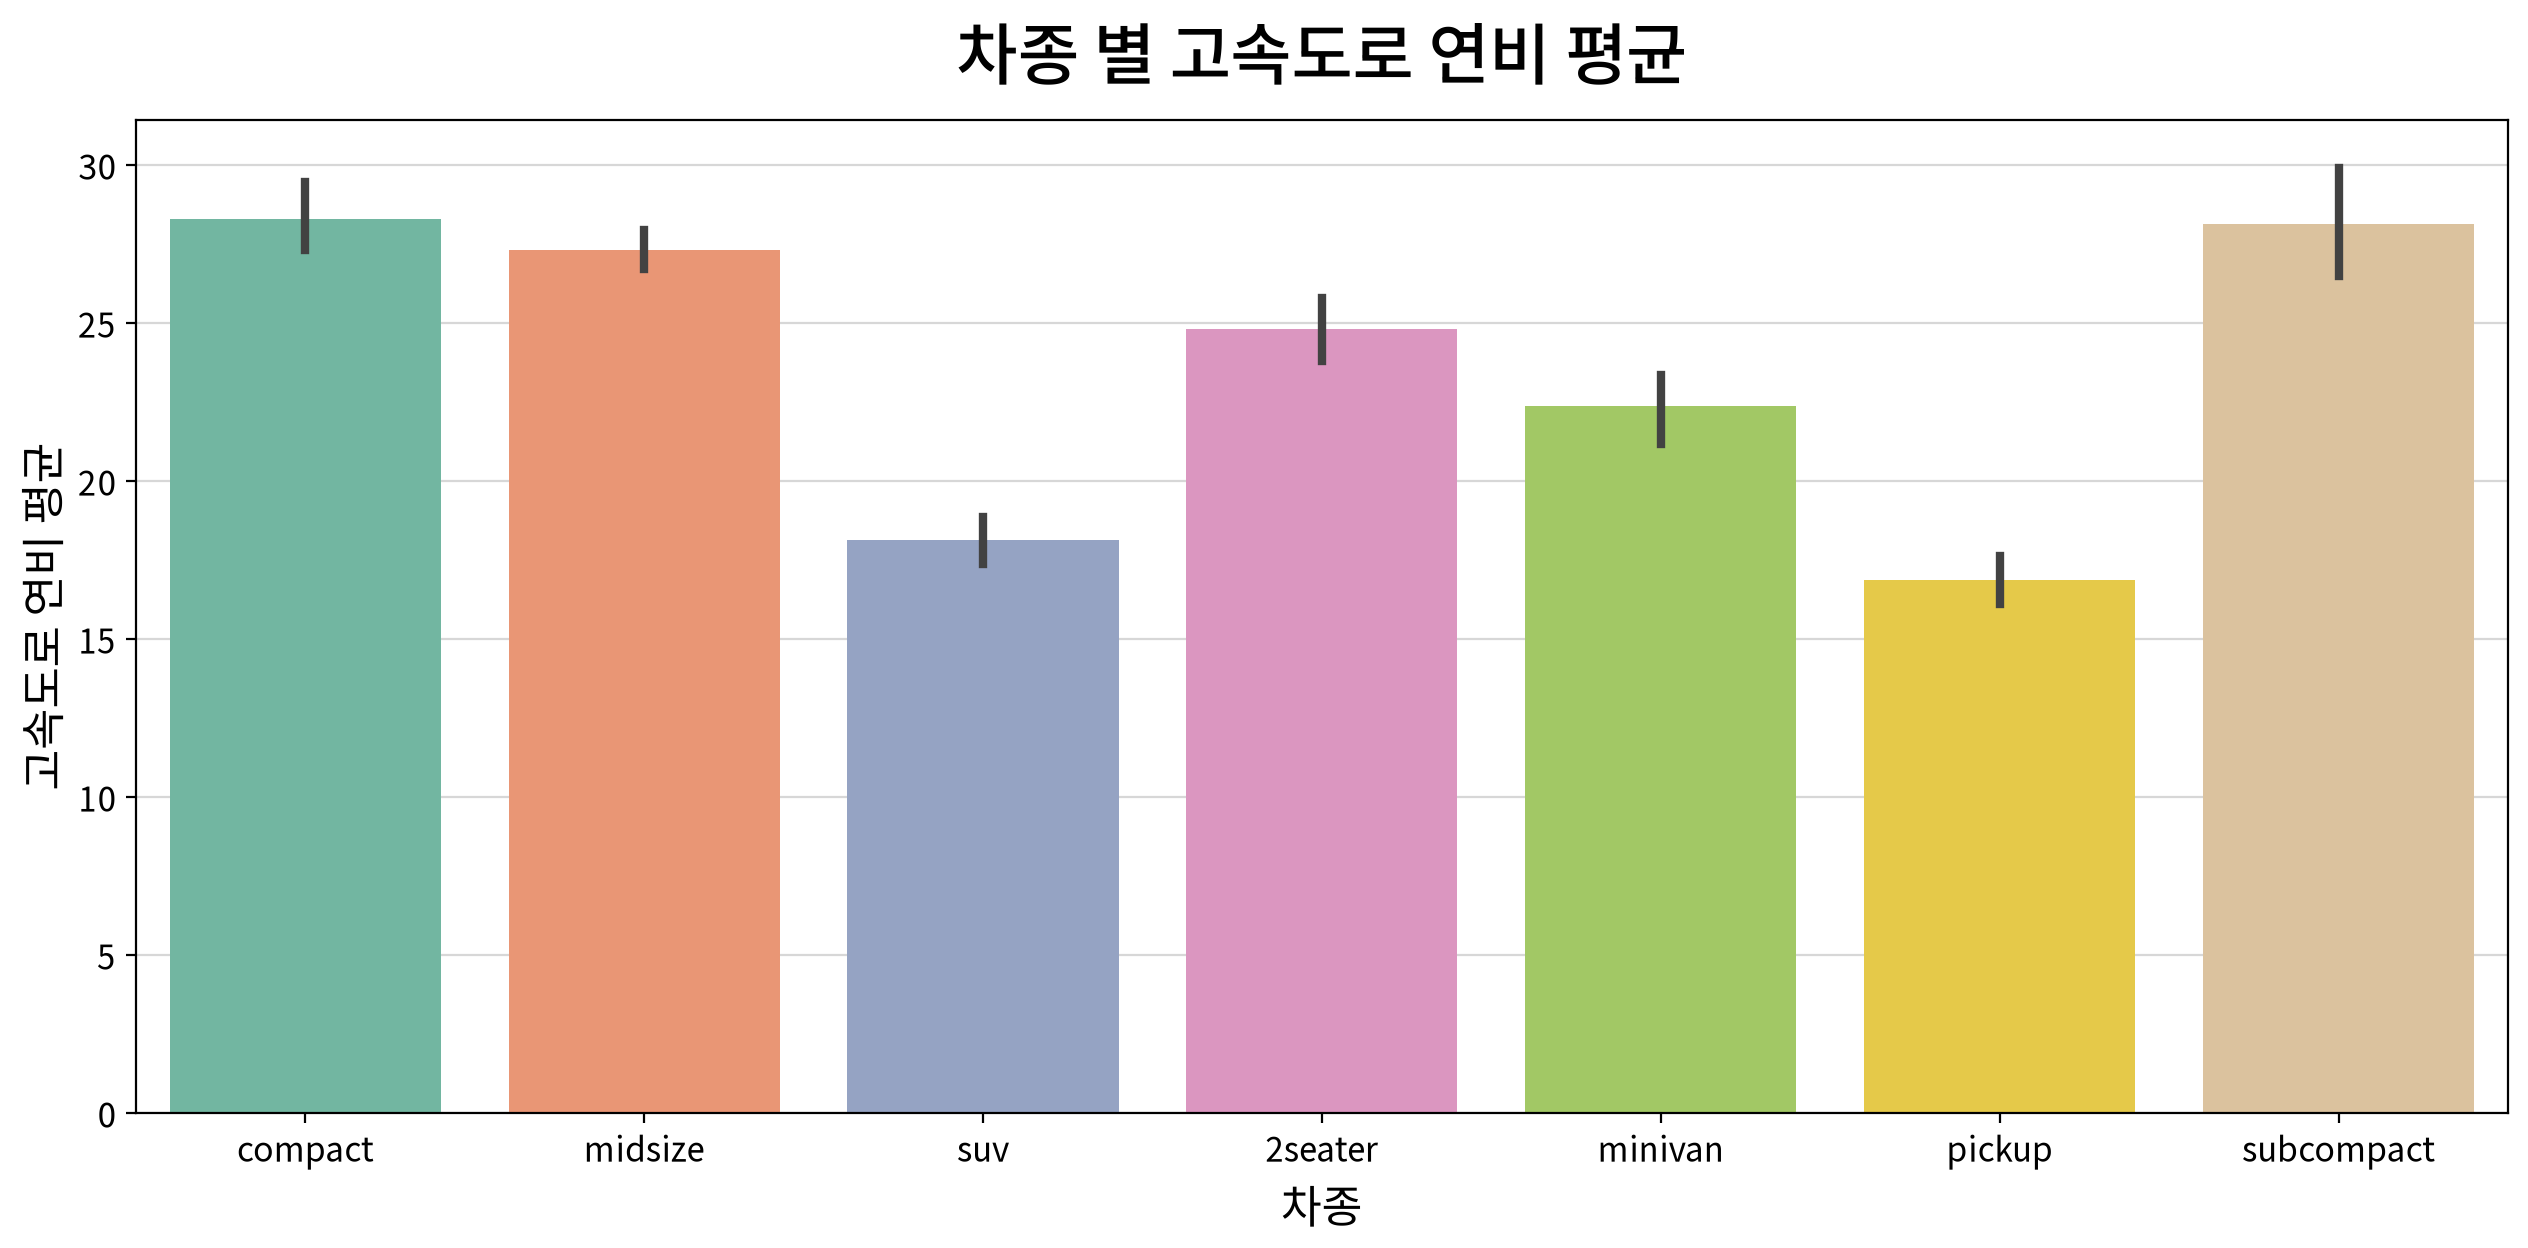

In [12]:
my_plot.barplot(data=df, x="class", y="hwy",
                estimator=np.mean, palette="Set2",
                title="차종 별 고속도로 연비 평균", xlabel="차종", ylabel="고속도로 연비 평균")

- ② pickup

## 문제 9. 차종(`class`) 중 고속도로 연비(`hwy`) 평균이 가장 높은 종류는?

① compact  ② subcompact  ③ midsize  ④ 2seater

> 💡 **힌트**: 막대그래프 (차종별 hwy 평균, 내림차순 정렬)

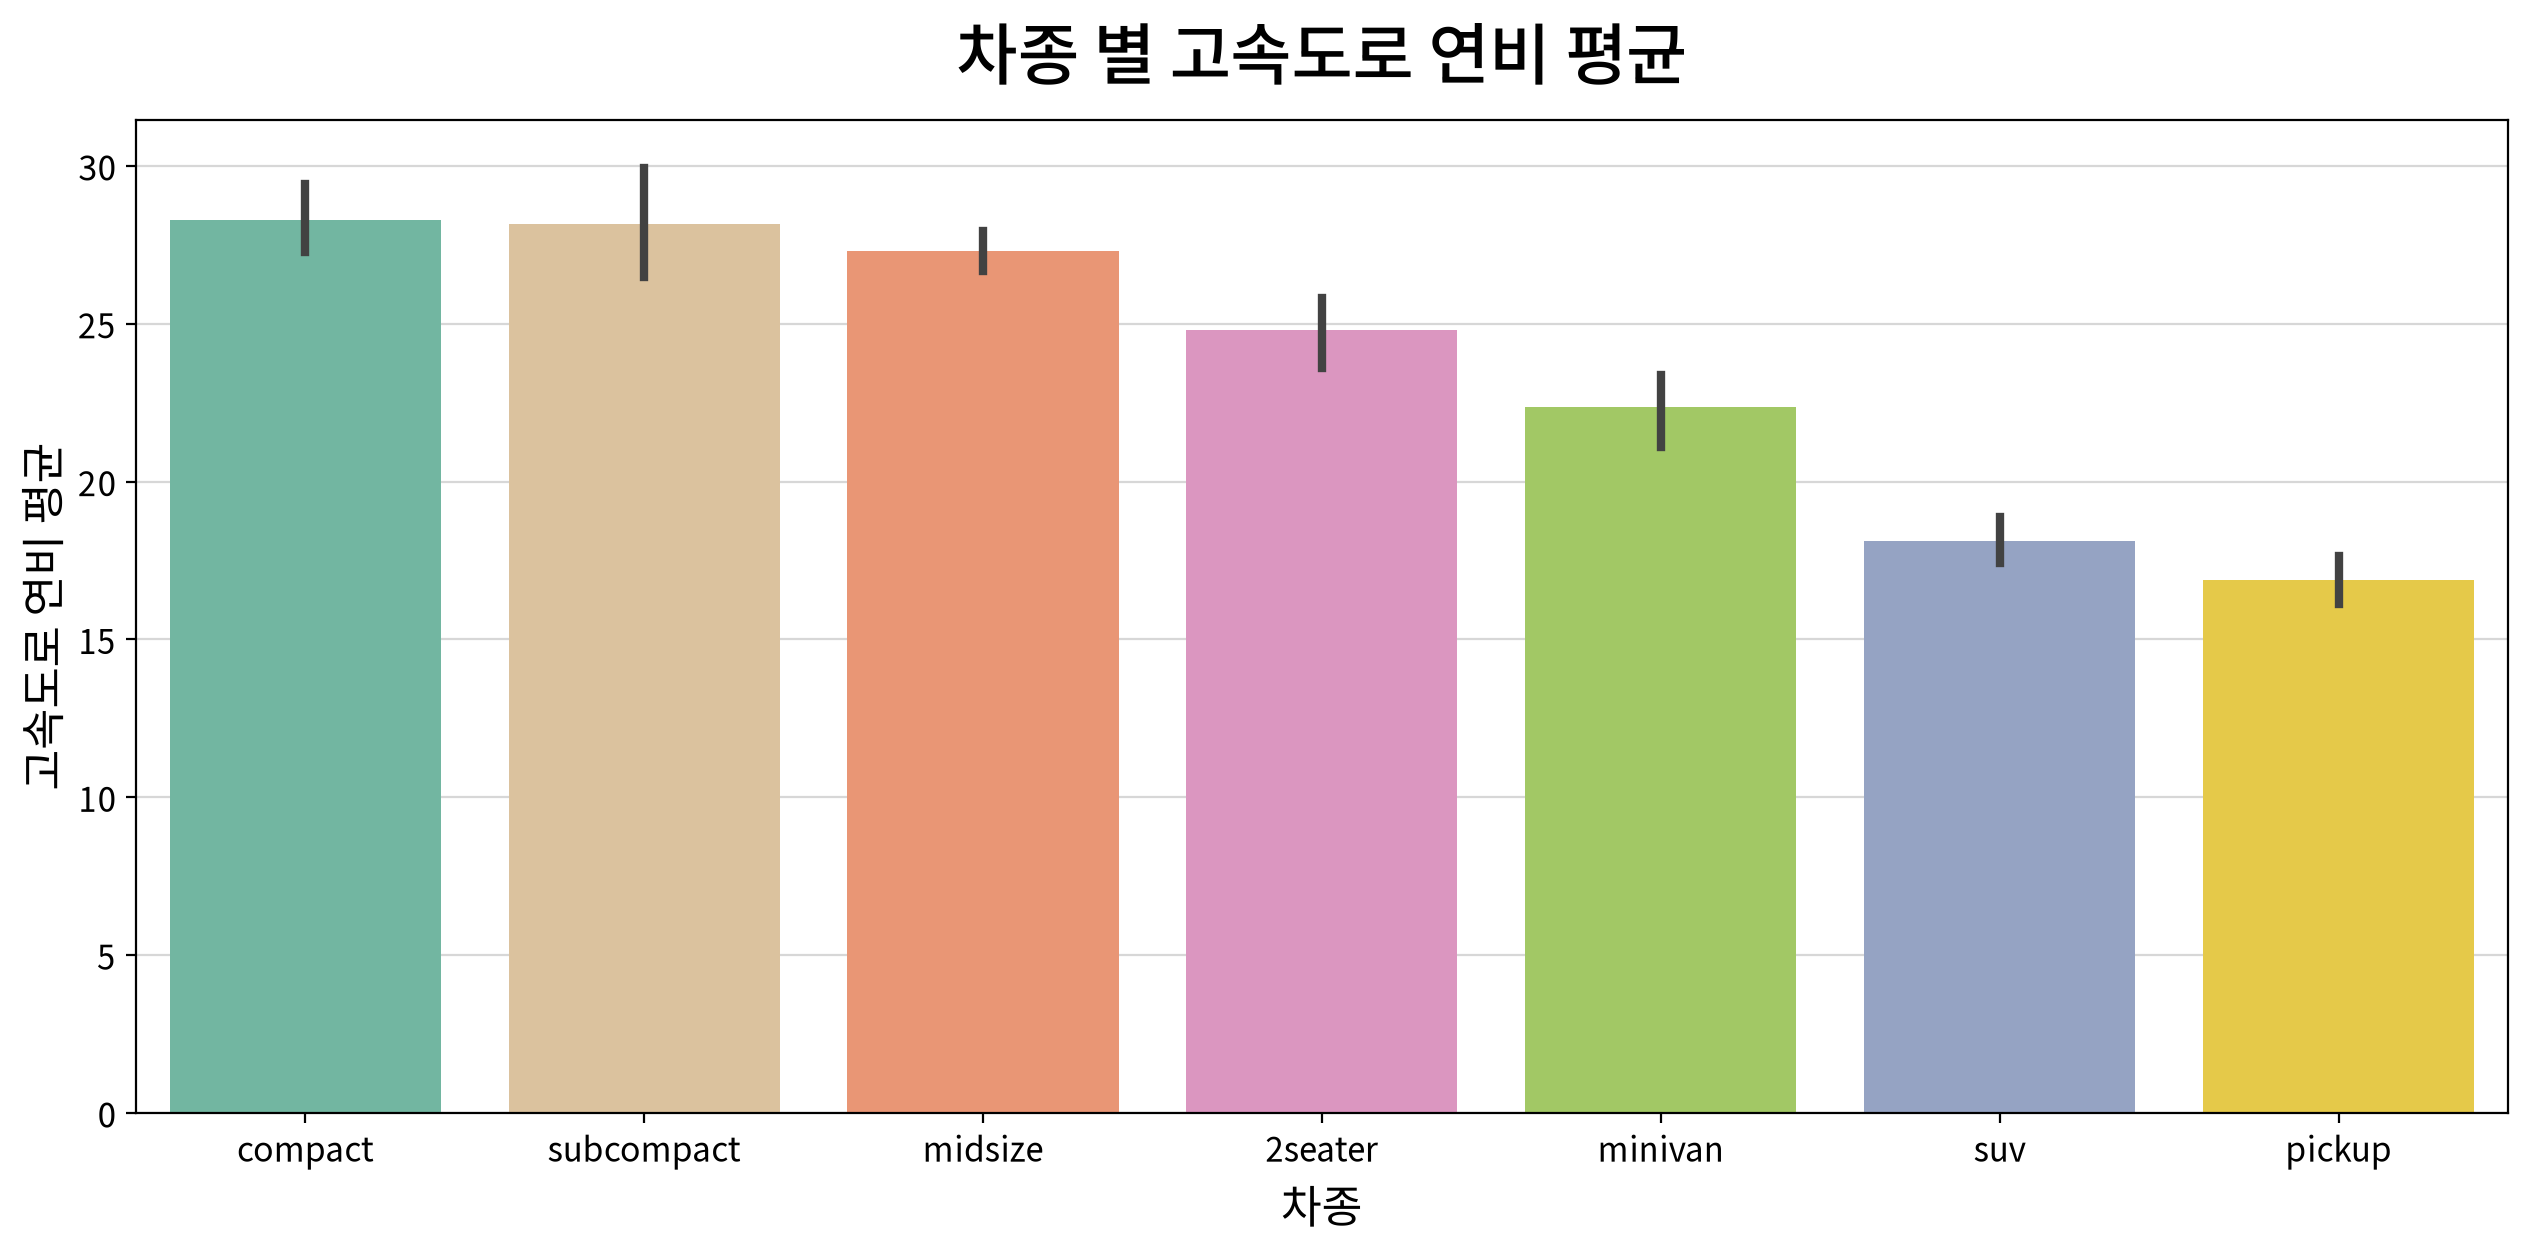

In [13]:
my_plot.barplot(data=df, x="class", y="hwy",
                order=df.groupby('class')['hwy']
                        .mean()
                        .sort_values(ascending=False)
                        .index,
                estimator=np.mean, palette="Set2",
                title="차종 별 고속도로 연비 평균", xlabel="차종", ylabel="고속도로 연비 평균")

- ① compact

## 문제 10. 도심 연비(`cty`) 평균이 가장 높은 제조사는?

① volkswagen  ② honda  ③ subaru  ④ hyundai

> 💡 **힌트**: 막대그래프 (제조사별 cty 평균)

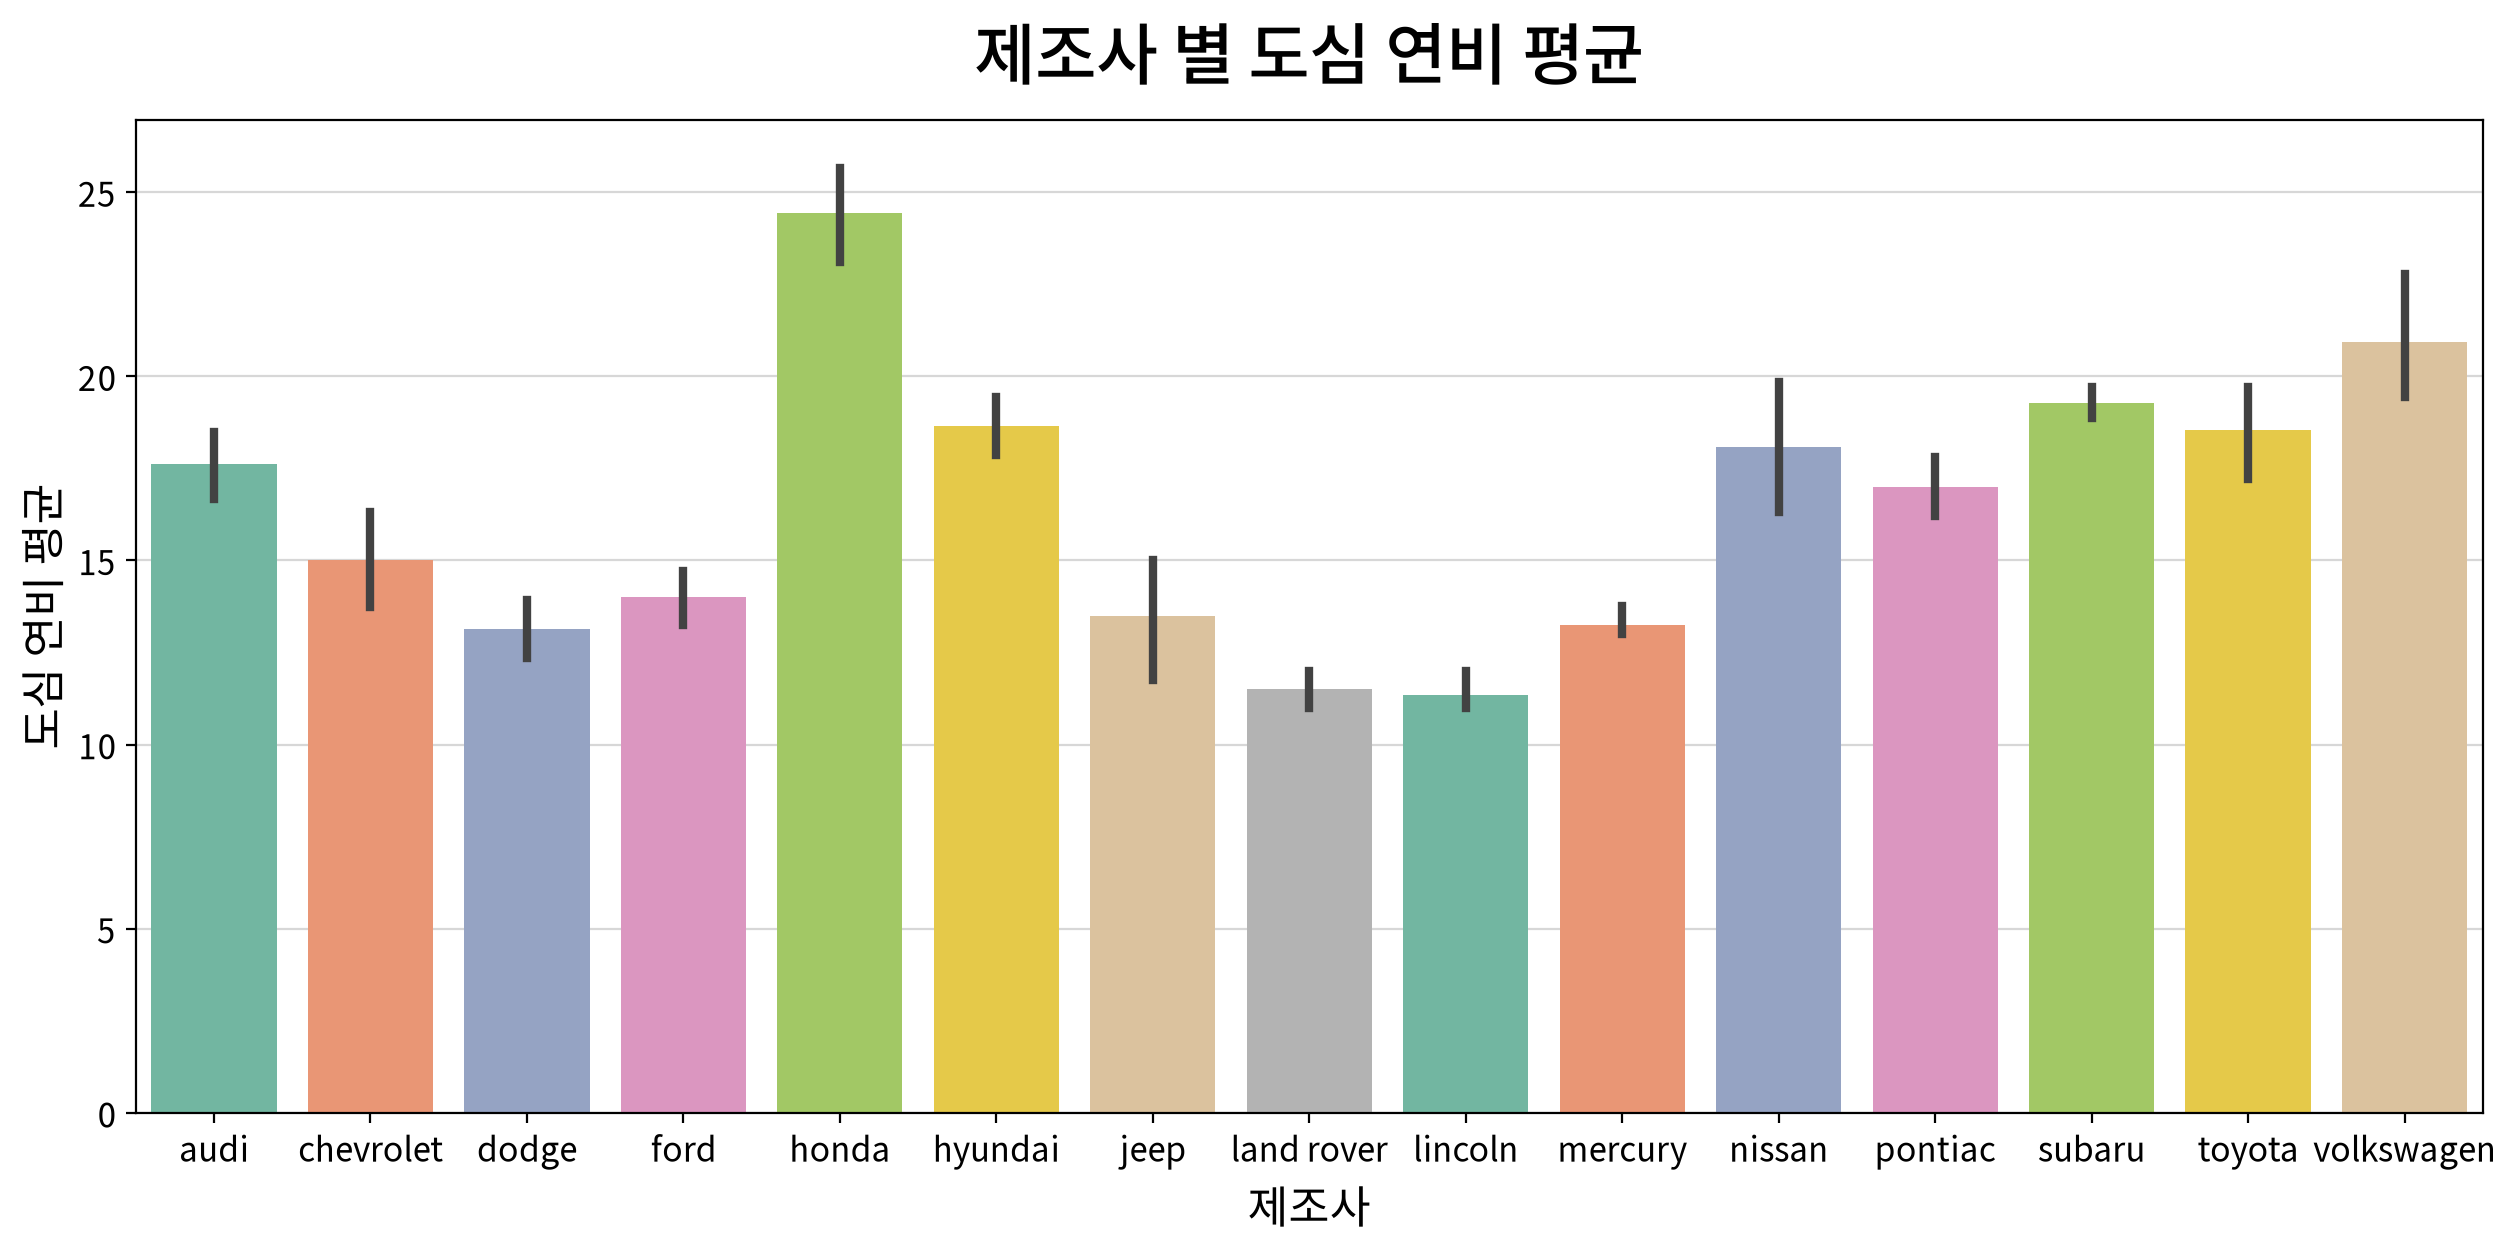

In [14]:
my_plot.barplot(data=df, x="manufacturer", y="cty",
                estimator=np.mean, palette="Set2",
                title="제조사 별 도심 연비 평균", xlabel="제조사", ylabel="도심 연비 평균")

- ② honda

## 문제 11. 고속도로 연비(`hwy`) 평균이 가장 낮은 제조사는?

① dodge  ② lincoln  ③ land rover  ④ jeep

> 💡 **힌트**: 막대그래프 (제조사별 hwy 평균)

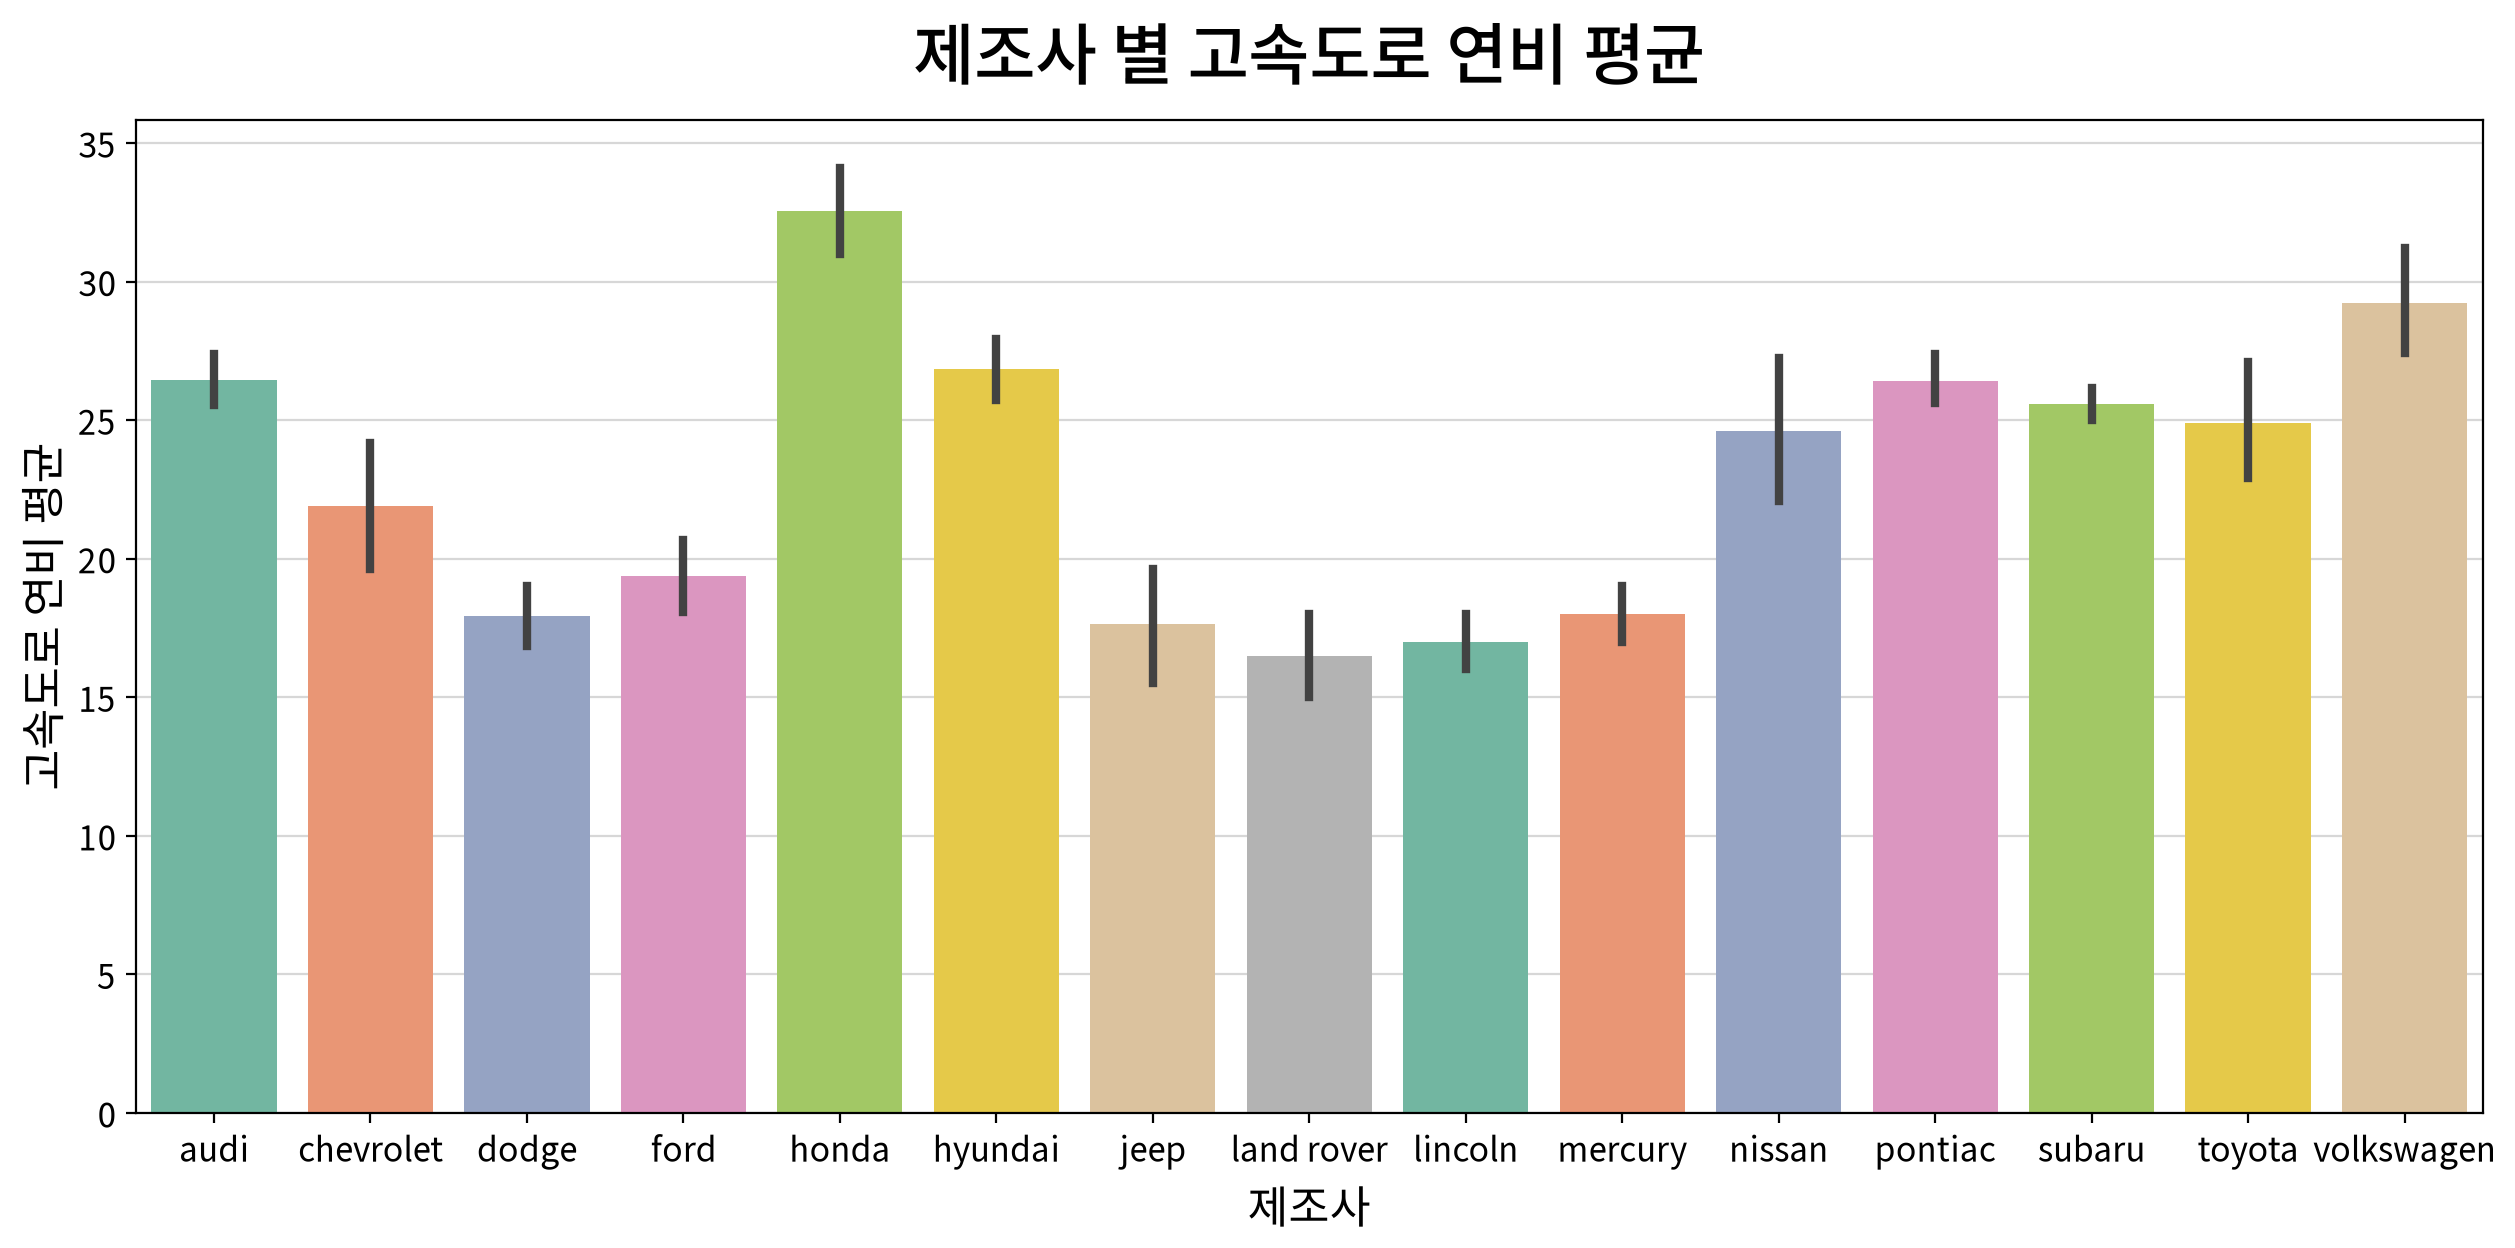

In [15]:
my_plot.barplot(data=df, x="manufacturer", y="hwy",
                estimator=np.mean, palette="Set2",
                title="제조사 별 고속도로 연비 평균", xlabel="제조사", ylabel="고속도로 연비 평균")

- ③ land rover

## 문제 12. 변속기 종류(자동 vs 수동)에 따른 연비 비교로 옳은 것은?

① 자동이 수동보다 연비가 높다  ② 수동이 자동보다 연비가 높다  ③ 차이가 없다  ④ 도심은 자동, 고속도로는 수동이 높다

> 💡 **힌트**: 막대그래프 (`trans`를 auto/manual로 묶은 뒤 cty·hwy 평균)

In [16]:
df1 = df.copy()

df1['trans'] = df['trans'].str.split("(").str[0]

pivot_df = df1.reset_index()
mdf = melt(pivot_df, id_vars=['id', 'trans'], value_vars=['cty', 'hwy'],
           var_name='연비 구분', value_name='연비')
mdf.head()

,id,trans,연비 구분,연비
0,1,auto,cty,18
1,2,manual,cty,21
2,3,manual,cty,20
3,4,auto,cty,21
4,5,auto,cty,16


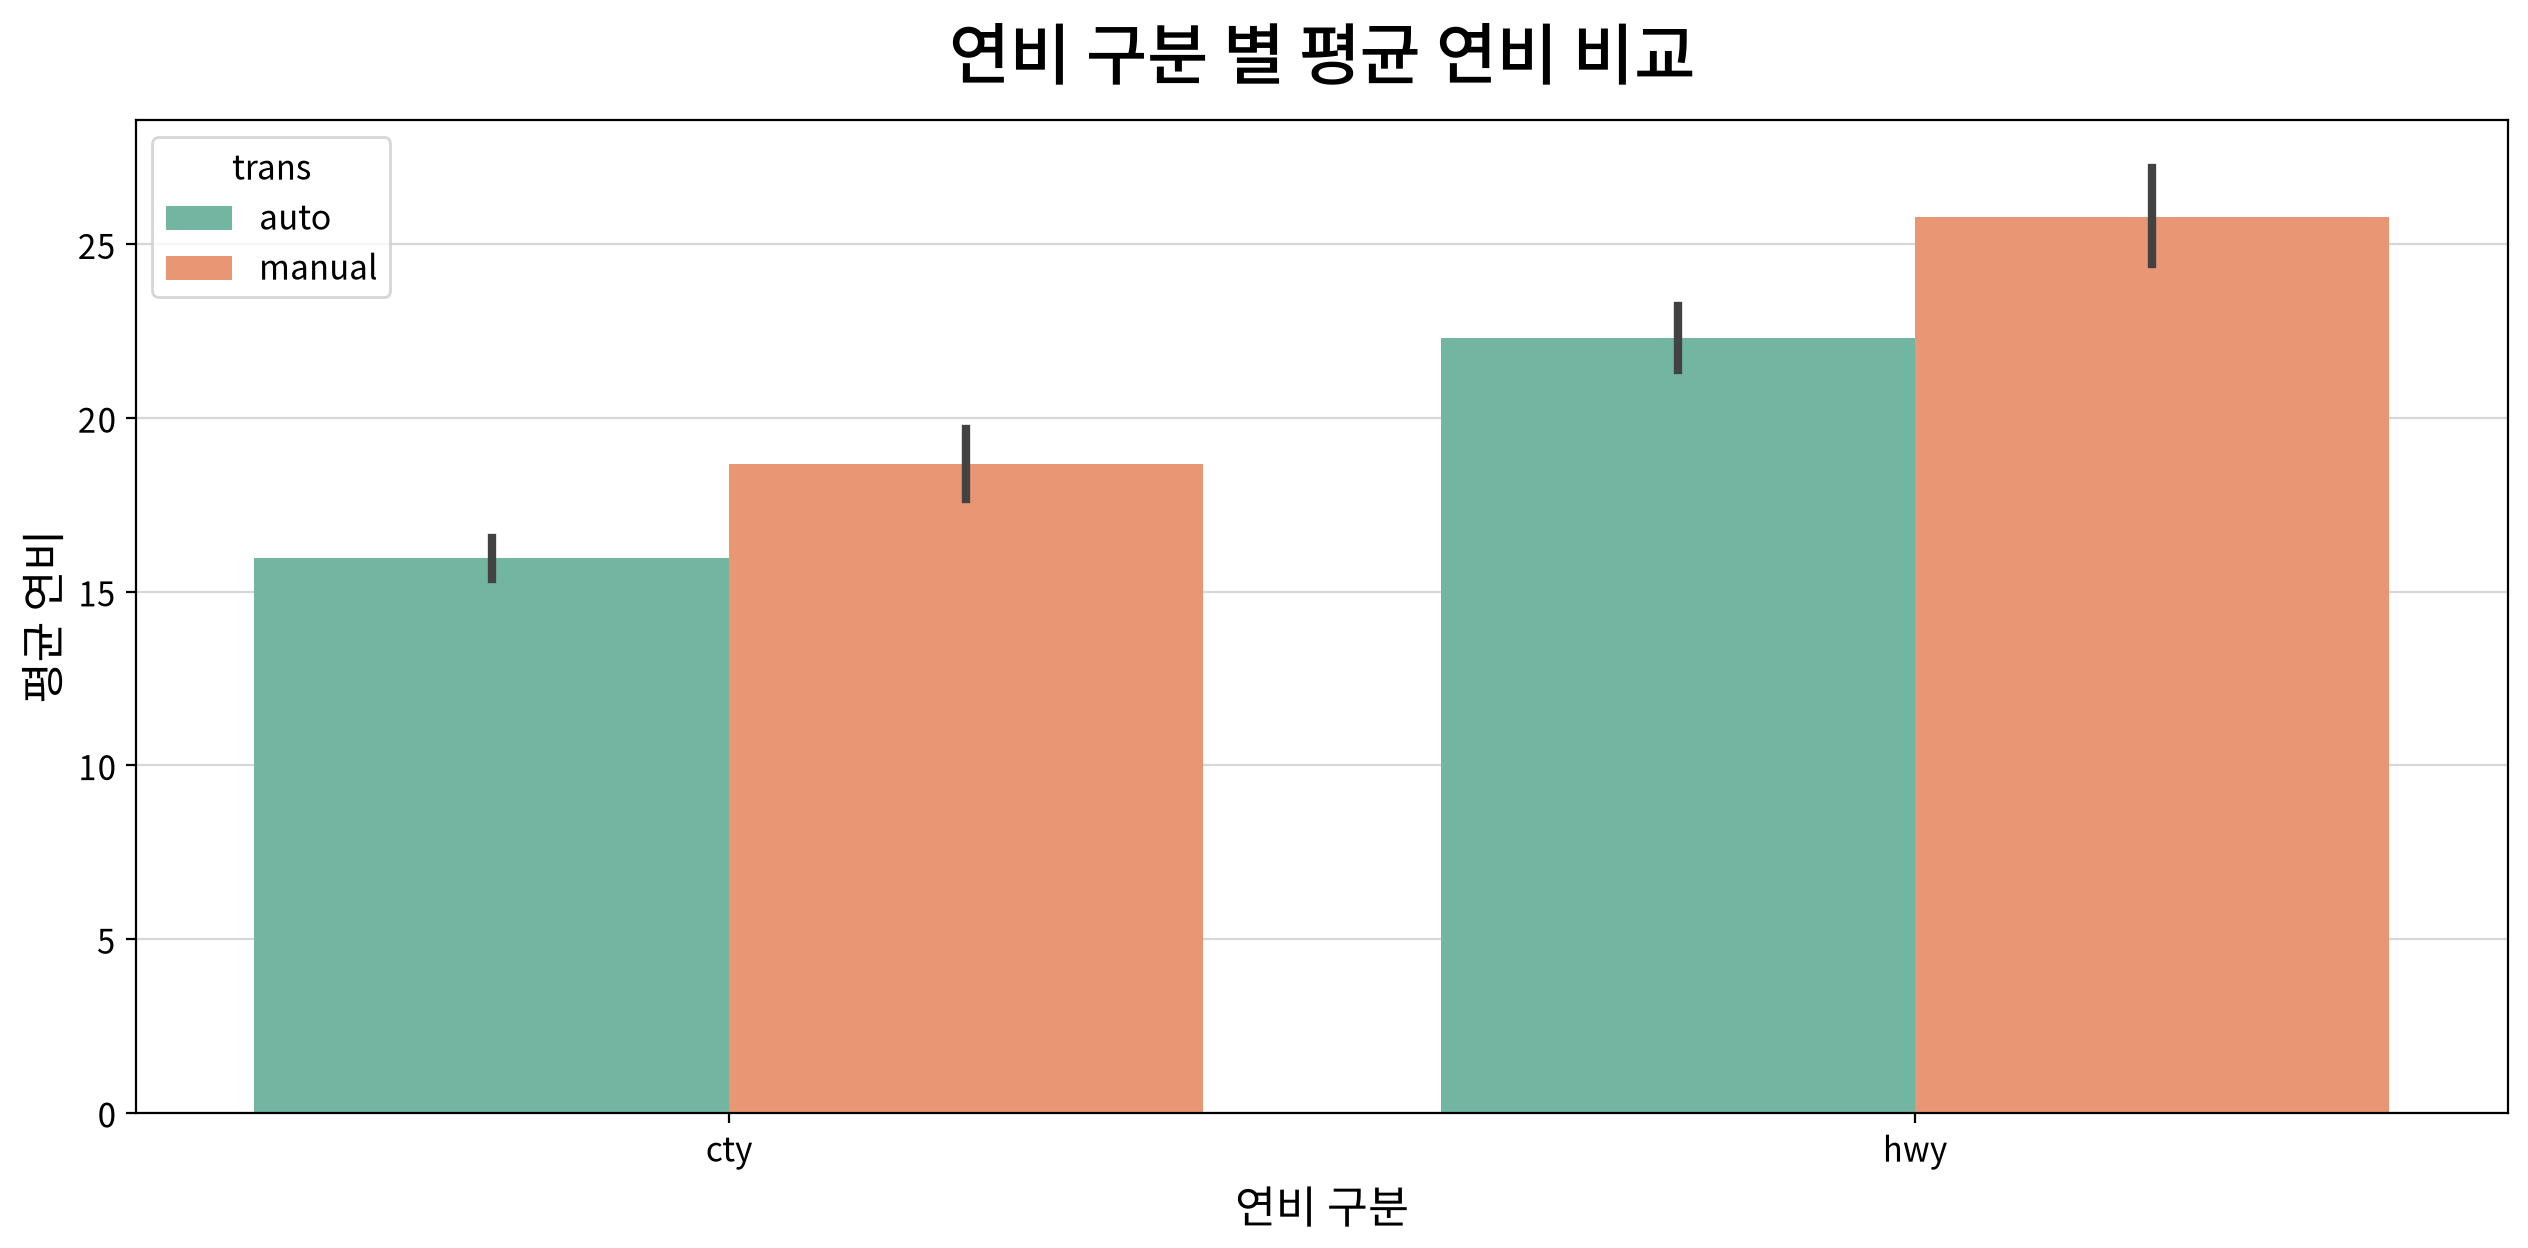

In [17]:
my_plot.barplot(data=mdf, x="연비 구분", y="연비", hue="trans",
                estimator=np.mean, palette="Set2",
                title="연비 구분 별 평균 연비 비교", xlabel="연비 구분", ylabel="평균 연비")

- ② 수동이 자동보다 연비가 높다

## 문제 13. 가장 많이 사용된 연료(`fl`) 종류는?

① p (프리미엄)  ② r (레귤러)  ③ e (에탄올)  ④ d (디젤)

> 💡 **힌트**: 막대그래프 또는 원그래프 (연료별 빈도)

In [18]:
df1['fl'].value_counts()

fl
r    168
p     52
e      8
d      5
c      1
Name: count, dtype: int64

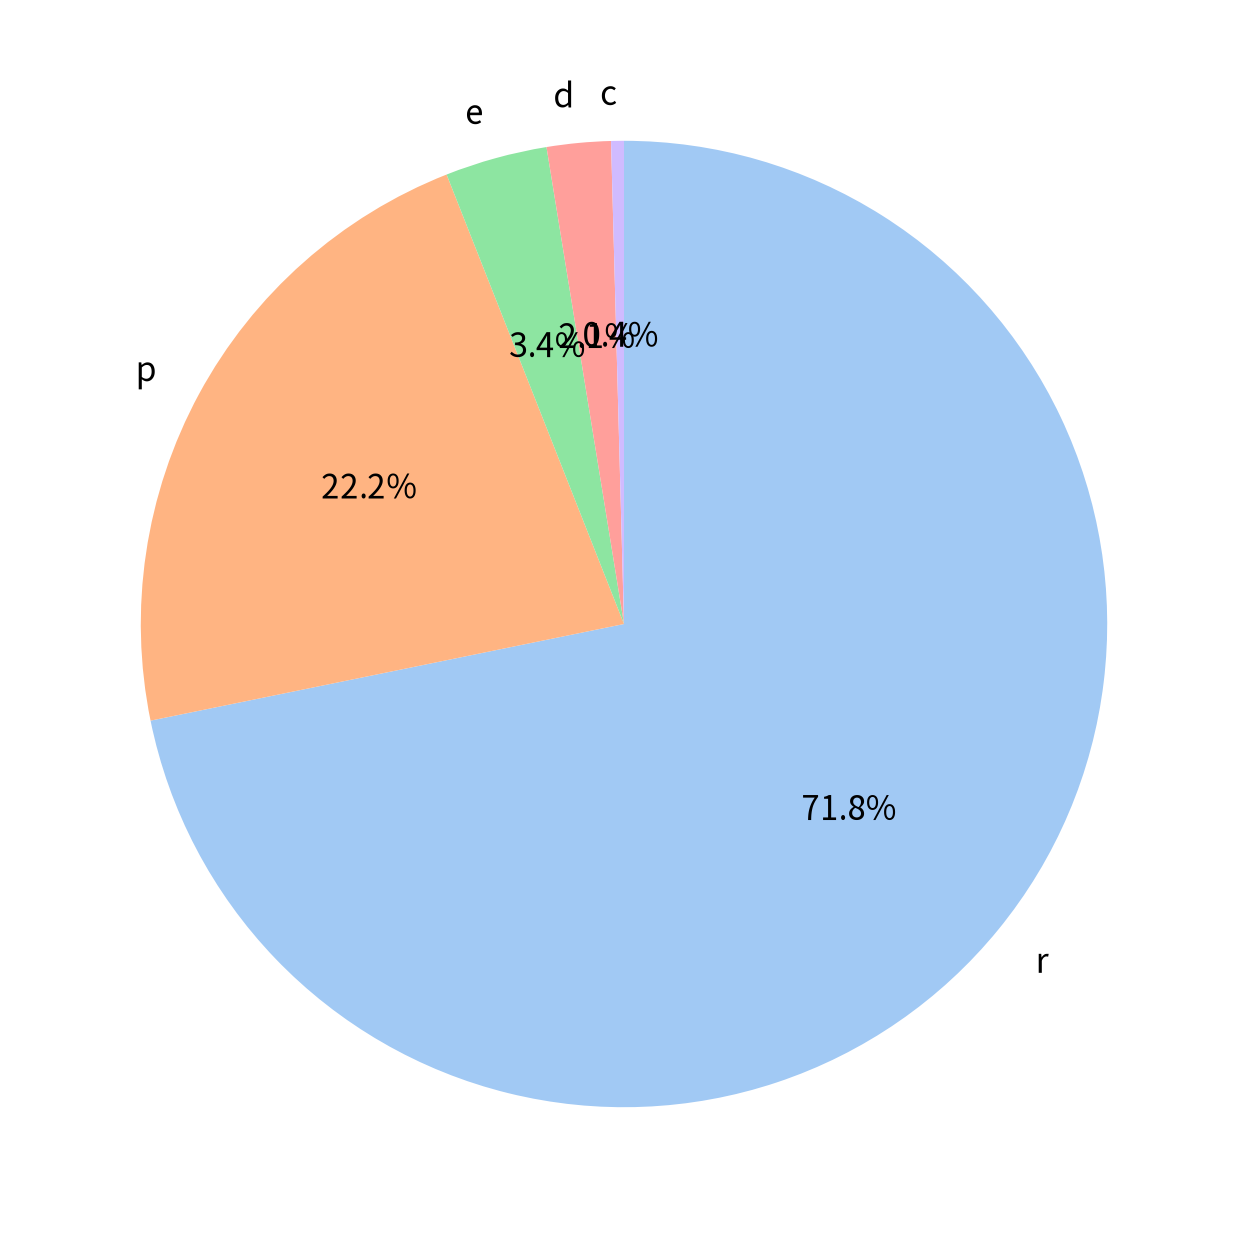

In [19]:
my_plot.pieplot(x=df['fl'].value_counts(), labels=df1['fl'].value_counts().index, palette="pastel")

- ② r (레귤러)

## 문제 14. 1999년과 2008년의 평균 고속도로 연비(`hwy`)를 비교하면?

① 2008년이 크게 향상되었다  ② 1999년이 더 높다  ③ 거의 차이가 없다  ④ 2008년이 절반 수준이다

> 💡 **힌트**: 막대그래프 (연식별 hwy 평균)

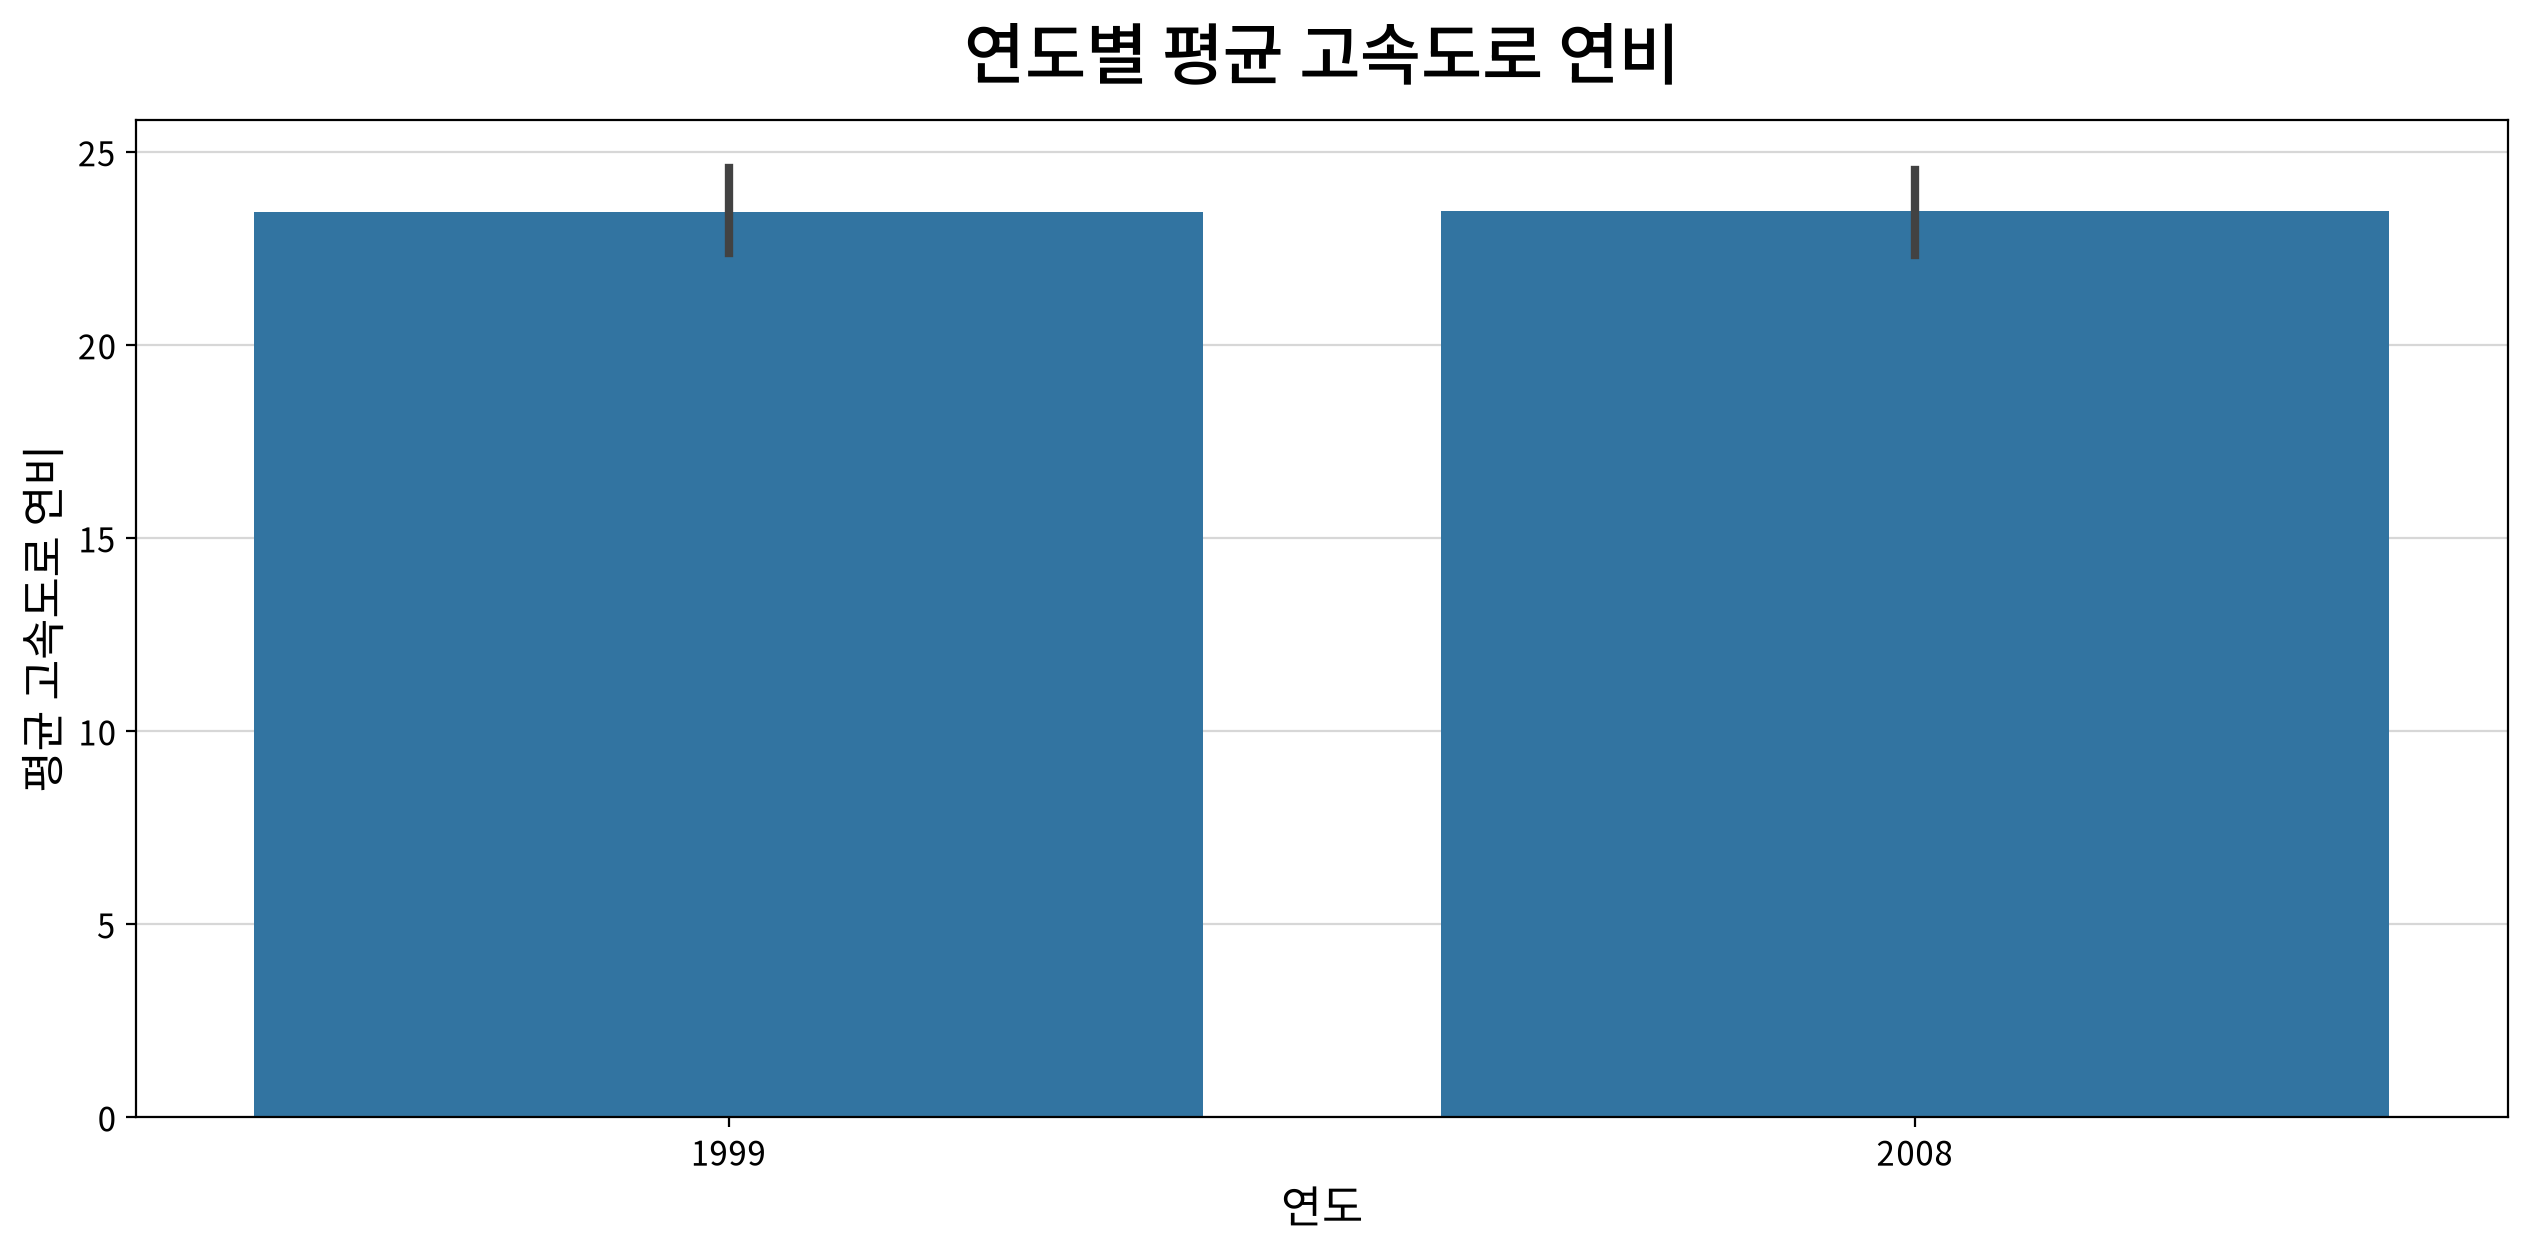

In [20]:
my_plot.barplot(data=df, x='year', y="hwy", estimator=np.mean,
                title="연도별 평균 고속도로 연비", xlabel="연도", ylabel="평균 고속도로 연비")

- ③ 거의 차이가 없다

## 문제 15. SUV 차종에는 존재하지 않는 구동방식은?

① 4륜구동  ② 후륜구동  ③ 전륜구동  ④ 모두 존재한다

> 💡 **힌트**: 막대그래프 (차종 SUV로 필터 후 구동방식별 빈도) 또는 교차표 시각화

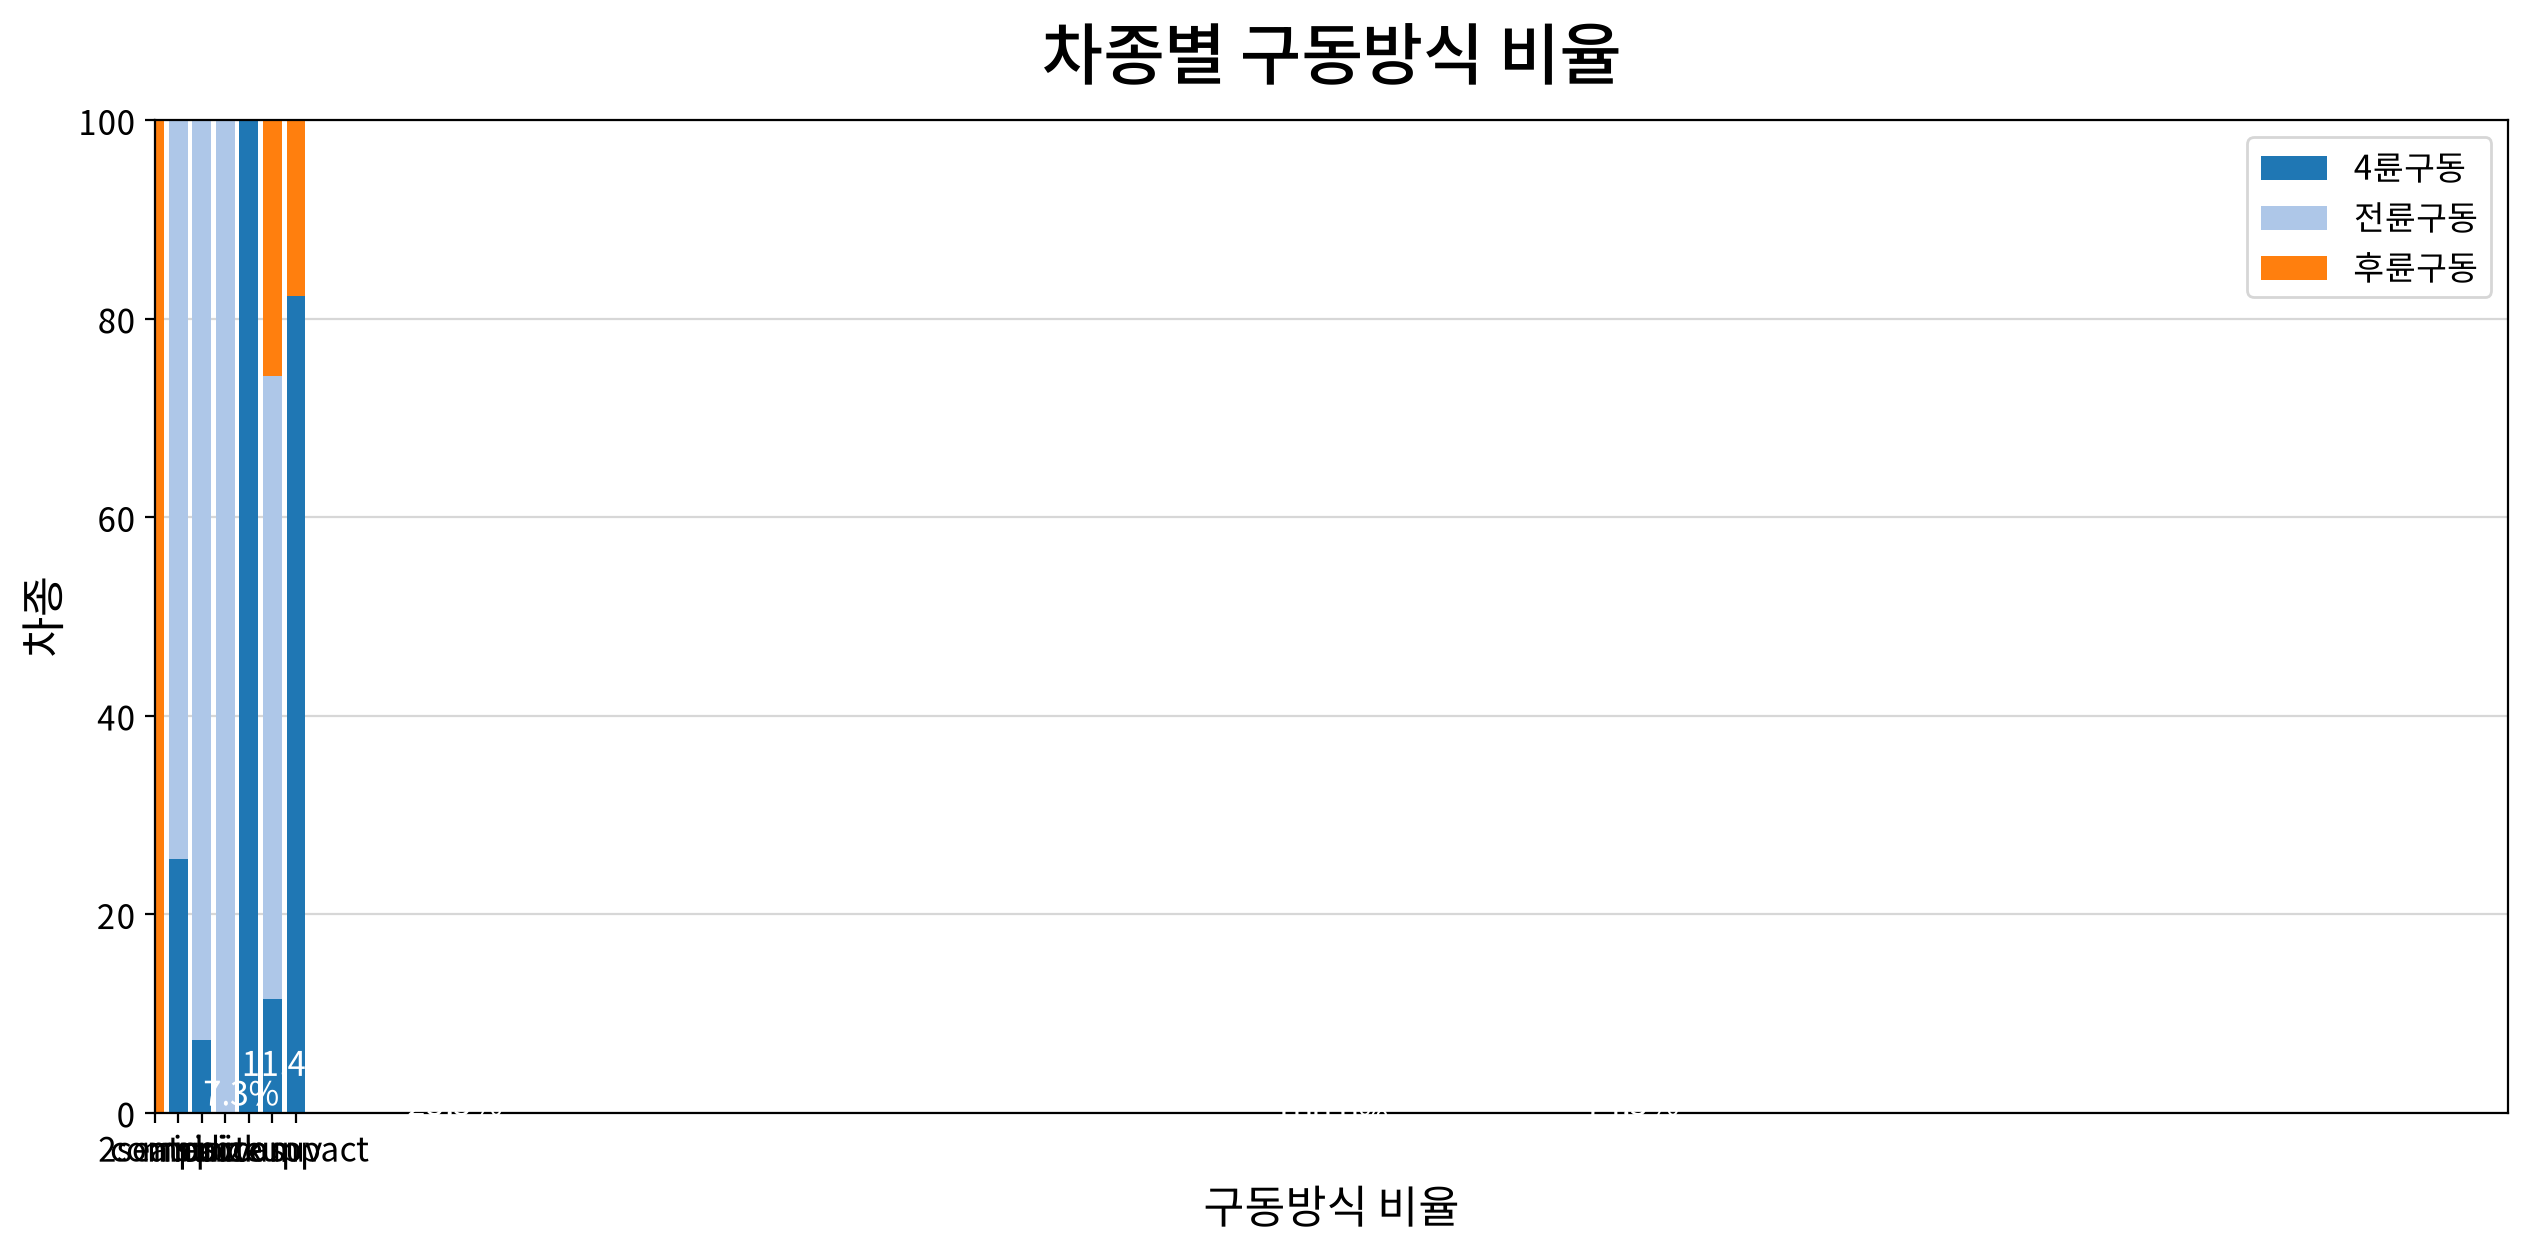

In [21]:
my_plot.stackplot(data=df, x="class", y="model", hue="drv",
                  aggfunc=np.size, orient='h', ratio=True, palette="tab20",
                  title="차종별 구동방식 비율", xlabel="구동방식 비율", ylabel="차종")

- ③ 전륜구동

## 문제 16. 픽업(pickup) 차종의 구동방식은?

① 모두 4륜구동  ② 모두 전륜구동  ③ 4륜·후륜 혼합  ④ 전륜·4륜 혼합

> 💡 **힌트**: 막대그래프 (차종 pickup으로 필터 후 구동방식별 빈도)

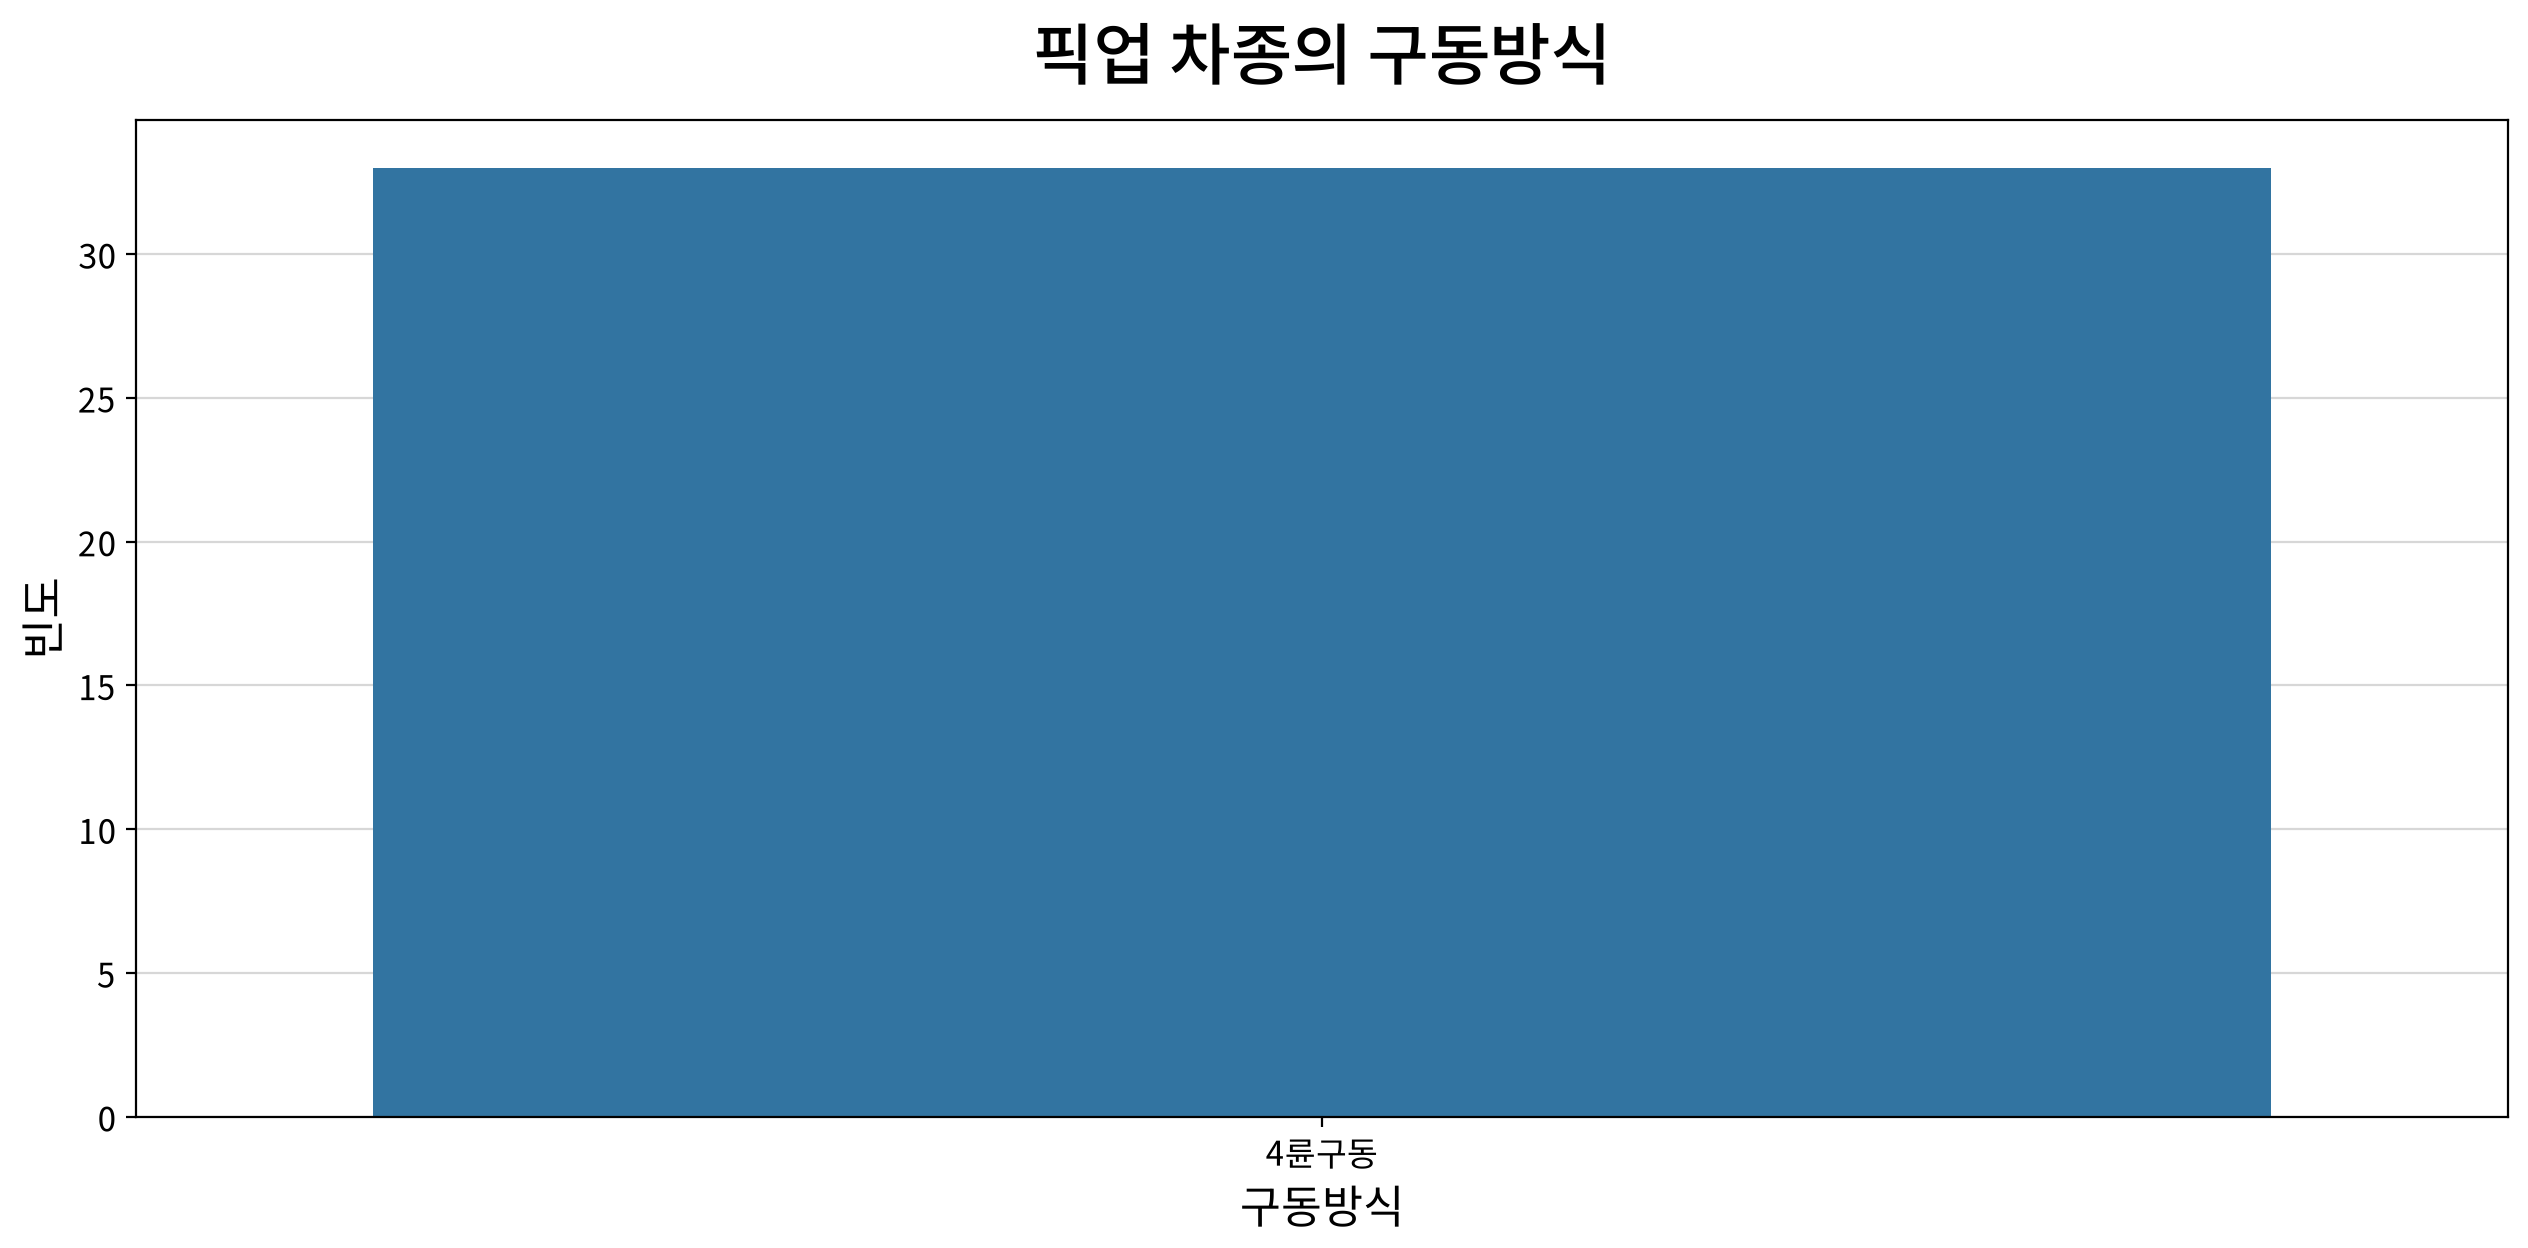

In [22]:
df_pickup = df[df['class'] == 'pickup']

my_plot.countplot(data=df_pickup, x="drv",
                  title="픽업 차종의 구동방식", xlabel="구동방식", ylabel="빈도")

## 문제 17. 평균연비 `(cty + hwy) / 2`가 전체 평균보다 높은(합격, Pass) 차량의 비율에 가장 가까운 값은?

① 약 25%  ② 약 47%  ③ 약 53%  ④ 약 75%

> 💡 **힌트**: 원그래프 (Pass/Fail 비율)

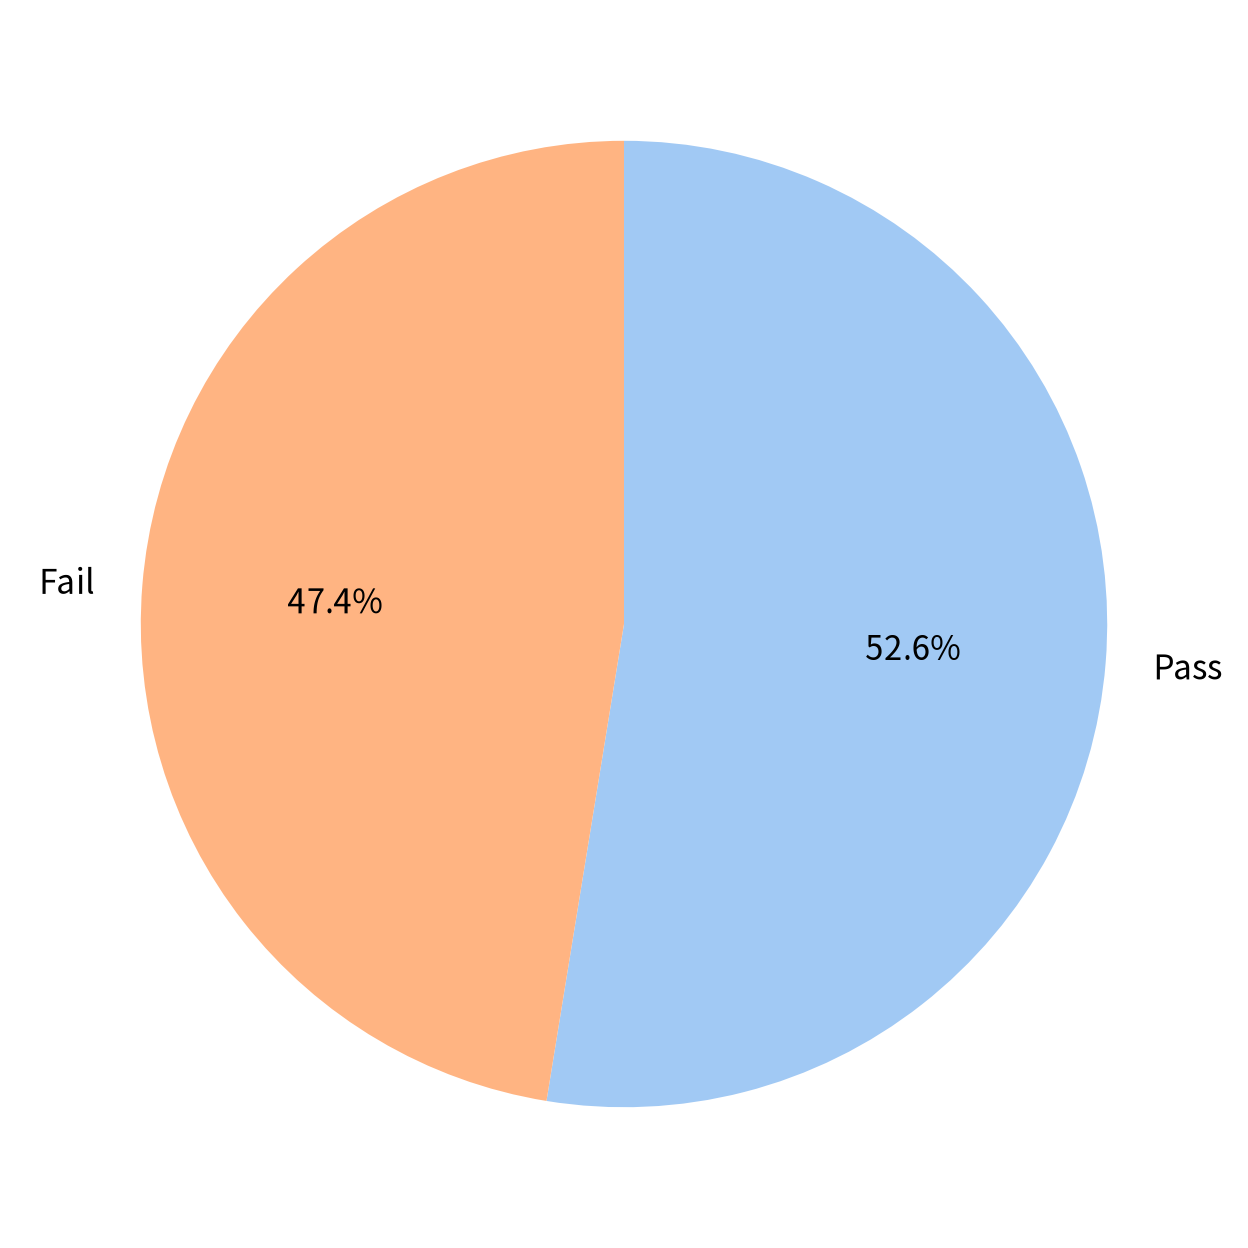

In [27]:
df['avg_y'] = (df['cty'] + df['hwy']) / 2
avg_all = df['avg_y'].mean()

ratio = []

for i in df['avg_y']:
    if i > avg_all:
        ratio.append("Pass")
    else:
        ratio.append("Fail")

df['ratio'] = ratio

my_plot.pieplot(x=df['ratio'].value_counts(), labels=df['ratio'].value_counts().index, palette="pastel")

- ③ 약 53%

## 문제 18. 배기량(`displ`) 분포의 중앙값(median)에 가장 가까운 값은?

① 2.4  ② 3.3  ③ 3.5  ④ 4.6

> 💡 **힌트**: 히스토그램 또는 박스플롯 (displ 분포)

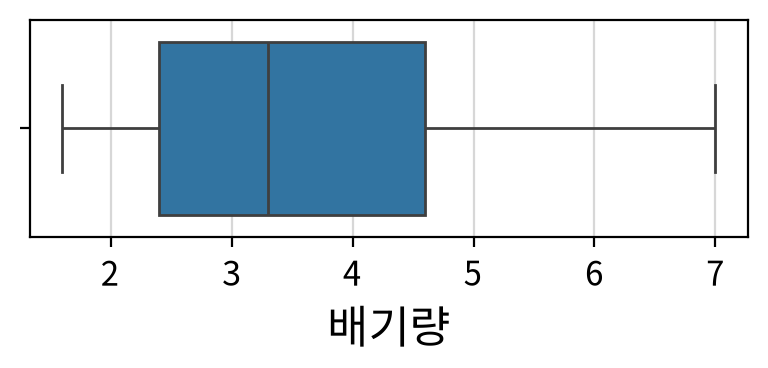

In [29]:
my_plot.boxplot(data=df, x='displ', xlabel="배기량",
                width=400, height=200)

- ② 3.3